## Bibliotecas

In [ ]:
# Bibliotecas para silenciar advertencias
import warnings
from pathlib import Path

# Bibliotecas para manejo de datos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliotecas para modelado
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error, r2_score)

# Silenciar advertencias
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid')

# Carpeta del proyecto
# Raíz del repositorio: se sube desde la carpeta actual hasta encontrar main.py
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "main.py").exists())
DATA_DIR = RAIZ / "data" / "modelado"
RANDOM_STATE = 42 # Semilla para reproducibilidad

# **Modelado Random Forest**
## Línea base con ensayo de Random Forest
- Un Random Forest con CV 5-fold aleatoria da R² ≈ 0.55 y MAE ≈ 0.43 t/ha (vs. 0.75 al predecir la media). `era5_vpd_medio_flor_kpa` acapara ≈ 39 % de la importancia.
- Con CV **agrupada por municipio** el R² cae a ≈ −0.31 y el MAE sube a ≈ 0.86 t/ha, peor que predecir la media: el modelo **no generaliza a municipios que no vio** y aprende sobre todo la zona.

## Recomendaciones para el modelado en Random Forest
Derivado del análisis del EDA, consideramos las siguientes recomendaciones para un modelo en Random Forest.

1. Como las 59 parcelas de predicción están en los mismos municipios que el entrenamiento, la CV aleatoria es válida para este split. 
2. Incluir las variables de identidad
3. Separar el efecto de zona: incluir la una nueva variable `grupo_rend` como una variable estratificadora de 5 splits.
4. Tratar el ruido de etiqueta: Incluir `diag_y_resolucion` como un ponderador de error (Utilizar sample_weight en el método .fit())
5. Se descartan las variables diagnóstico`diag_fenologia_discrepante`, `diag_topo_nodata`, `diag_sin_ciclo`, `diag_ciclo_ambiguo`, `diag_s2_sin_ciclo` y `diag_era5_vecino` como variables de control para Random Forest.
6. Incluir `diag_topo_pocos_pix` como *feature* (columna binaria, es decir, 1 y 0) en la matriz de características predictoras ($X$) al momento de entrenar.
7. Eliminar de las variables predictoras las redundancias exactas (`pl_eos20_doy`, `ac_dias_lluvia_ciclo`, `pl_sos20_doy`, `era5_rs_ciclo_mj_m2`, `pend_p90_grados`, `s2_ndvi_int_abr_oct`, `pl_ndvi_pico`, `s2_centro_pico_doy`, `ac_lluvia_llen_mm`, `era5_apar_ciclo_mj_m2`, `ac_lluvia_ciclo_anom_mm`)
8. Columnas a incluir en preprocesamiento: 
    - Metadatos: id_poligono, municipio, estado, conjunto, clima_pixel_id
    - Variable objetivo: rendimiento_t_ha
    - Variables predictoras: era5_vpd_medio_flor_kpa, ac_lluvia_pre_mm, era5_sm2_flor, soil_agua_disp_mm, soil_soc_g_kg, pl_eos50_doy, soil_densidad_g_cm3, ac_gdd_ciclo, pl_amplitud, soil_limo_pct, era5_vpd_medio_llen_kpa, pl_ndvi_base, pl_ndvi_int_abr_oct, ac_gdd_hasta_flor, era5_sm2_min_llen, elev_media_m , pl_dias_meseta, era5_tmax_media_flor_c, AREA_HA, pl_lai_int_ciclo, pend_max_grados, pend_media_grados, pl_lai_max_ciclo, pl_centro_pico_doy, pl_tasa_subida, soil_arena_pct, s2_sos50_doy, pl_caida_intra_ciclo, pl_sos50_doy, era5_sm2_llen, ac_lluvia_veg_mm, era5_sm1_siembra, ac_racha_seca_max_flor, era5_apar_post_pico_mj_m2, s2_ndvi_pico, ac_lluvia_ciclo_anom_rel, ac_balance_llen_mm, elev_std_m, ac_balance_flor_mm, dz_pixel_m, pl_n_picos, soil_ph, ac_balance_ciclo_mm, ac_lluvia_max_dia_ciclo_mm, ac_racha_seca_max_ciclo, pl_integral_ciclo, ac_lluvia_ciclo_mm, soil_arcilla_pct, s2_integral_ciclo, pl_tasa_bajada
    - Variable diagnóstico:`diag_topo_pocos_pix`
    - Variable estratificadora: `grupo_rend`(creada a partir de closterizar rendimientos)
    - Variable ponderadora: `diag_y_resolucion` 

## 1. Carga, roles de columnas y separación de conjuntos

Los roles se definen explícitamente para evitar *data leakage*:

| Rol | Columnas | Uso |
|---|---|---|
| Metadatos | `id_poligono`, `municipio`, `estado`, `conjunto`, `clima_pixel_id` | Identificación / reconstrucción final |
| Estratificación | `grupo_rend` | **Solo** para generar los cortes de `StratifiedKFold` |
| Pesos | `diag_y_resolucion` | Escalón de redondeo del dato (0.01 = preciso, 0.5 = redondeado). **Solo** se usa transformado en peso de precisión (`sample_weight` y métricas ponderadas) |
| Objetivo | `rendimiento_t_ha` | `y` |
| Predictoras | Resto de columnas numéricas (incluye `diag_topo_pocos_pix`) | `X` |

In [2]:
df = pd.read_csv(DATA_DIR / 'dataset_greedy.csv')
print(f'Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas')
assert df.shape[0] == 197, 'Se esperaban 197 observaciones'

cols_metadatos      = ['id_poligono', 'municipio', 'estado', 'conjunto', 'clima_pixel_id']
col_estratificacion = 'grupo_rend'
col_pesos           = 'diag_y_resolucion'
col_target          = 'rendimiento_t_ha'

cols_excluidas   = cols_metadatos + [col_estratificacion, col_pesos, col_target]
cols_predictoras = [c for c in df.columns
                    if c not in cols_excluidas and pd.api.types.is_numeric_dtype(df[c])]

# Verificaciones explícitas anti-fuga
assert not set(cols_predictoras) & set(cols_excluidas), 'Fuga: columnas excluidas dentro de X'
assert 'diag_topo_pocos_pix' in cols_predictoras, 'diag_topo_pocos_pix debe ser predictora'
sin_rol = [c for c in df.columns if c not in cols_excluidas + cols_predictoras]
assert not sin_rol, f'Columnas sin rol asignado: {sin_rol}'

N_VARS = len(cols_predictoras)
print(f'Número de variables predictoras: {N_VARS}')
print(f'¿Metadatos en X? {bool(set(cols_metadatos) & set(cols_predictoras))} | '
      f"¿'{col_estratificacion}' en X? {col_estratificacion in cols_predictoras} | "
      f"¿'{col_pesos}' en X? {col_pesos in cols_predictoras} | "
      f"¿'{col_target}' en X? {col_target in cols_predictoras}")

Dataset cargado: 197 filas x 59 columnas
Número de variables predictoras: 51
¿Metadatos en X? False | ¿'grupo_rend' en X? False | ¿'diag_y_resolucion' en X? False | ¿'rendimiento_t_ha' en X? False


### 1.1 Verificación de las 51 predictoras

En `Preprocesamiento_RandomForest.ipynb` se definieron **50** variables en `PREDICTORAS` y, aparte, `diag_topo_pocos_pix` en `DIAGNOSTICO` (binaria, usada como *feature*). Por eso `X` tiene **50 + 1 = 51** columnas. La celda siguiente lo comprueba contra la lista de referencia del preprocesamiento.

In [3]:
PREDICTORAS_REF_50 = [
    "era5_vpd_medio_flor_kpa", "ac_lluvia_pre_mm", "era5_sm2_flor", "soil_agua_disp_mm", "soil_soc_g_kg",
    "pl_eos50_doy", "soil_densidad_g_cm3", "ac_gdd_ciclo", "pl_amplitud", "soil_limo_pct",
    "era5_vpd_medio_llen_kpa", "pl_ndvi_base", "pl_ndvi_int_abr_oct", "ac_gdd_hasta_flor", "era5_sm2_min_llen",
    "elev_media_m", "pl_dias_meseta", "era5_tmax_media_flor_c", "area_ha_geod", "pl_lai_int_ciclo",
    "pend_max_grados", "pend_media_grados", "pl_lai_max_ciclo", "pl_centro_pico_doy", "pl_tasa_subida",
    "soil_arena_pct", "s2_sos50_doy", "pl_caida_intra_ciclo", "pl_sos50_doy", "era5_sm2_llen",
    "ac_lluvia_veg_mm", "era5_sm1_siembra", "ac_racha_seca_max_flor", "era5_apar_post_pico_mj_m2", "s2_ndvi_pico",
    "ac_lluvia_ciclo_anom_rel", "ac_balance_llen_mm", "elev_std_m", "ac_balance_flor_mm", "dz_pixel_m",
    "pl_n_picos", "soil_ph", "ac_balance_ciclo_mm", "ac_lluvia_max_dia_ciclo_mm", "ac_racha_seca_max_ciclo",
    "pl_integral_ciclo", "ac_lluvia_ciclo_mm", "soil_arcilla_pct", "s2_integral_ciclo", "pl_tasa_bajada",
]
DIAGNOSTICO_REF = ['diag_topo_pocos_pix']

print(f'{N_VARS} columnas en X:')
for i, c in enumerate(cols_predictoras, 1):
    origen = 'DIAGNOSTICO (feature binaria)' if c in DIAGNOSTICO_REF else 'PREDICTORAS'
    print(f'  {i:2d}. {c:30s} [{origen}]')

extra    = set(cols_predictoras) - set(PREDICTORAS_REF_50) - set(DIAGNOSTICO_REF)
faltante = set(PREDICTORAS_REF_50 + DIAGNOSTICO_REF) - set(cols_predictoras)
assert len(PREDICTORAS_REF_50) == 50 and not extra and not faltante, f'extra={extra} | faltante={faltante}'
print(f'\n✔ X = 50 PREDICTORAS + 1 DIAGNOSTICO = {N_VARS} columnas; sin variables indebidas.')

51 columnas en X:
   1. era5_vpd_medio_flor_kpa        [PREDICTORAS]
   2. ac_lluvia_pre_mm               [PREDICTORAS]
   3. era5_sm2_flor                  [PREDICTORAS]
   4. soil_agua_disp_mm              [PREDICTORAS]
   5. soil_soc_g_kg                  [PREDICTORAS]
   6. pl_eos50_doy                   [PREDICTORAS]
   7. soil_densidad_g_cm3            [PREDICTORAS]
   8. ac_gdd_ciclo                   [PREDICTORAS]
   9. pl_amplitud                    [PREDICTORAS]
  10. soil_limo_pct                  [PREDICTORAS]
  11. era5_vpd_medio_llen_kpa        [PREDICTORAS]
  12. pl_ndvi_base                   [PREDICTORAS]
  13. pl_ndvi_int_abr_oct            [PREDICTORAS]
  14. ac_gdd_hasta_flor              [PREDICTORAS]
  15. era5_sm2_min_llen              [PREDICTORAS]
  16. elev_media_m                   [PREDICTORAS]
  17. pl_dias_meseta                 [PREDICTORAS]
  18. era5_tmax_media_flor_c         [PREDICTORAS]
  19. area_ha_geod                   [PREDICTORAS]
  20. pl_lai_

In [4]:
df_train = df[df['conjunto'] == 'ENTRENAMIENTO'].copy()
df_pred  = df[df['conjunto'] == 'PREDICCION'].copy()
assert len(df_train) == 138 and len(df_pred) == 59

X_train = df_train[cols_predictoras]
y_train = df_train[col_target]
res_train = df_train[col_pesos]   # escalón de redondeo original (NO entra en X)
X_pred  = df_pred[cols_predictoras]

assert X_train.notna().all().all() and X_pred.notna().all().all(), 'Hay NaN en predictoras'
assert y_train.notna().all() and res_train.notna().all(), 'Hay NaN en target o resolución de entrenamiento'

print(f'df_train: {df_train.shape} | X_train: {X_train.shape} | y_train: {y_train.shape} | res_train: {res_train.shape}')
print(f'df_pred : {df_pred.shape} | X_pred : {X_pred.shape}')
print('\nDistribución de grupo_rend (entrenamiento):')
print(df_train[col_estratificacion].value_counts().to_string())
# diag_y_resolucion es el escalón de redondeo del rendimiento: a menor escalón, mayor precisión.
# Se transforma a un peso de precisión moderado (no anula a ningún grupo):
#   0.01 -> 1.0 | 0.1 -> 0.7 | >= 0.5 -> 0.5
def resolucion_a_peso(res):
    res = np.asarray(res, float)
    assert np.isin(res, [0.01, 0.1]).sum() + (res >= 0.5).sum() == len(res), 'Resolución no contemplada'
    return np.select([np.isclose(res, 0.01), np.isclose(res, 0.1), res >= 0.5], [1.0, 0.7, 0.5])

w_precision = pd.Series(resolucion_a_peso(res_train), index=df_train.index, name='w_precision')

print('\nTransformación diag_y_resolucion -> peso de precisión:')
display(pd.crosstab([res_train.rename('diag_y_resolucion'), w_precision], df_train['grupo_rend'], margins=True))
print('Suma de pesos por grupo (proporción del peso total):')
print((w_precision.groupby(df_train['grupo_rend']).sum() / w_precision.sum()).round(3).to_string())

df_train: (138, 59) | X_train: (138, 51) | y_train: (138,) | res_train: (138,)
df_pred : (59, 59) | X_pred : (59, 51)

Distribución de grupo_rend (entrenamiento):
grupo_rend
Alto    80
Bajo    58

Transformación diag_y_resolucion -> peso de precisión:


,grupo_rend,Alto,Bajo,All
diag_y_resolucion,w_precision,,,
0.01,1.0,73,7,80
0.1,0.7,6,7,13
0.5,0.5,1,44,45
All,,80,58,138


Suma de pesos por grupo (proporción del peso total):
grupo_rend
Alto    0.696
Bajo    0.304


## 2. RF línea base (todas las variables) y validación cruzada ponderada

Hiperparámetros fijos y `StratifiedKFold(5)` estratificado por `grupo_rend`. Los **mismos** `splits` se reutilizan en todo el notebook (modelo base, curva Top-K y modelo reducido), de modo que las comparaciones son pareadas. En cada pliegue el modelo se entrena con `sample_weight=w_tr`, donde `w_train` es el esquema de pesos elegido en la sección 2.1.

Las métricas **ponderadas** se calculan siempre con los pesos de precisión (`w_eval = w_precision`), para que los dos esquemas se evalúen con el mismo criterio.

In [5]:
rf_params = {
    'n_estimators': 300,
    'max_depth': 5,
    'min_samples_leaf': 4,
    'max_features': 'sqrt',
    'max_samples': 0.85,
    'random_state': 42,
    'n_jobs': -1
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
splits = list(skf.split(X_train, df_train['grupo_rend']))

for i, (tr, va) in enumerate(splits, 1):
    print(f'Pliegue {i}: train={len(tr):3d} | val={len(va):2d} | '
          f"val Alto/Bajo = {df_train['grupo_rend'].iloc[va].value_counts().to_dict()}")

Pliegue 1: train=110 | val=28 | val Alto/Bajo = {'Alto': 16, 'Bajo': 12}
Pliegue 2: train=110 | val=28 | val Alto/Bajo = {'Alto': 16, 'Bajo': 12}
Pliegue 3: train=110 | val=28 | val Alto/Bajo = {'Alto': 16, 'Bajo': 12}
Pliegue 4: train=111 | val=27 | val Alto/Bajo = {'Alto': 16, 'Bajo': 11}
Pliegue 5: train=111 | val=27 | val Alto/Bajo = {'Alto': 16, 'Bajo': 11}


In [6]:
def calcular_metricas(y_true, y_hat, w=None):
    # RMSE, MAE, MAPE (%) y R²; si se pasa w, versión ponderada por w
    y_true, y_hat = np.asarray(y_true, float), np.asarray(y_hat, float)
    return {
        'RMSE': np.sqrt(mean_squared_error(y_true, y_hat, sample_weight=w)),
        'MAE':  mean_absolute_error(y_true, y_hat, sample_weight=w),
        'MAPE': mean_absolute_percentage_error(y_true, y_hat, sample_weight=w) * 100,
        'R2':   r2_score(y_true, y_hat, sample_weight=w),
    }


def cv_ponderada(X, y, w, splits, params=rf_params, verbose=True):
    # Validación cruzada manual: cada pliegue se entrena con sample_weight=w_tr.
    # Devuelve las predicciones Out-Of-Fold y un DataFrame de métricas por pliegue.
    y_oof = np.full(len(y), np.nan)
    filas = []
    for k, (tr, va) in enumerate(splits, 1):
        X_tr, X_va = X.iloc[tr], X.iloc[va]
        y_tr, y_va = y.iloc[tr], y.iloc[va]
        w_tr = w.iloc[tr]

        modelo = RandomForestRegressor(**params)
        modelo.fit(X_tr, y_tr, sample_weight=w_tr)

        y_oof[va] = modelo.predict(X_va)
        m_tr = calcular_metricas(y_tr, modelo.predict(X_tr))
        m_va = calcular_metricas(y_va, y_oof[va])
        filas.append({'pliegue': k,
                      **{f'{m}_train': v for m, v in m_tr.items()},
                      **{f'{m}_val': v for m, v in m_va.items()}})
    df_folds = pd.DataFrame(filas).set_index('pliegue')
    assert not np.isnan(y_oof).any()
    if verbose:
        display(df_folds.round(4))
    return y_oof, df_folds


def resumen_cv(y, y_oof, w, df_folds, nombre):
    glob = pd.DataFrame({'Simple': calcular_metricas(y, y_oof),
                         'Ponderada (precisión)': calcular_metricas(y, y_oof, w)}).T
    print(f'=== {nombre} | Métricas globales Out-Of-Fold (n={len(y)}) ===')
    display(glob.round(4))

    filas = []
    for m in ['RMSE', 'MAE', 'MAPE', 'R2']:
        tr, va = df_folds[f'{m}_train'], df_folds[f'{m}_val']
        filas.append({'Métrica': m,
                      'Entrenamiento (media ± sd)': f'{tr.mean():.4f} ± {tr.std():.4f}',
                      'Validación (media ± sd)':    f'{va.mean():.4f} ± {va.std():.4f}',
                      'Brecha (val - train)':        round(va.mean() - tr.mean(), 4)})
    print(f'=== {nombre} | Promedio de los 5 pliegues: entrenamiento vs validación ===')
    display(pd.DataFrame(filas).set_index('Métrica'))
    return glob

### 2.1 Comparación rápida de esquemas de pesos

Se comparan, con los mismos `splits` y `rf_params` y con las 51 variables:
- **Pesos de precisión corregidos** (1.0 / 0.7 / 0.5).
- **Sin `sample_weight`** (todos los pesos = 1.0).

Se queda el esquema con menor RMSE OOF simple. Con el mismo `y`, el R² simple es una función decreciente del RMSE (R² = 1 − MSE/Var(y)), así que ambos criterios eligen lo mismo.

In [7]:
w_uniforme = pd.Series(1.0, index=df_train.index, name='w_uniforme')
w_eval = w_precision   # pesos con los que se calculan siempre las métricas ponderadas

esquemas = {'Precisión corregida (1.0/0.7/0.5)': w_precision,
            'Sin sample_weight (1.0)': w_uniforme}
filas = []
for nombre, w in esquemas.items():
    y_oof_tmp, folds_tmp = cv_ponderada(X_train, y_train, w, splits, verbose=False)
    m, m_w = calcular_metricas(y_train, y_oof_tmp), calcular_metricas(y_train, y_oof_tmp, w_eval)
    filas.append({'Esquema': nombre, 'RMSE_OOF': m['RMSE'], 'MAE_OOF': m['MAE'], 'MAPE_OOF': m['MAPE'],
                  'R2_OOF': m['R2'], 'RMSE_OOF_pond': m_w['RMSE'], 'R2_OOF_pond': m_w['R2'],
                  'R2_train_medio': folds_tmp['R2_train'].mean(), 'R2_val_medio': folds_tmp['R2_val'].mean()})
df_esquemas = pd.DataFrame(filas).set_index('Esquema')
display(df_esquemas.round(4))

esquema_elegido = df_esquemas['RMSE_OOF'].idxmin()
assert esquema_elegido == df_esquemas['R2_OOF'].idxmax()
w_train = esquemas[esquema_elegido]
print(f'Esquema elegido: {esquema_elegido}  '
      f"(RMSE OOF = {df_esquemas.loc[esquema_elegido, 'RMSE_OOF']:.4f}, "
      f"R² OOF = {df_esquemas.loc[esquema_elegido, 'R2_OOF']:.4f})")

,RMSE_OOF,MAE_OOF,MAPE_OOF,R2_OOF,RMSE_OOF_pond,R2_OOF_pond,R2_train_medio,R2_val_medio
Esquema,,,,,,,,
Precisión corregida (1.0/0.7/0.5),0.5801,0.4468,12.9138,0.5321,0.5875,0.4517,0.7799,0.5335
Sin sample_weight (1.0),0.5797,0.4522,12.9327,0.5327,0.5897,0.4475,0.7765,0.5334


Esquema elegido: Sin sample_weight (1.0)  (RMSE OOF = 0.5797, R² OOF = 0.5327)


In [8]:
y_oof_50vars, folds_50vars = cv_ponderada(X_train, y_train, w_train, splits)
metricas_50vars = resumen_cv(y_train, y_oof_50vars, w_eval, folds_50vars,
                             f'RF línea base ({N_VARS} variables)')

r2_tr, r2_va = folds_50vars['R2_train'].mean(), folds_50vars['R2_val'].mean()
print(f'Diagnóstico de sobreajuste: R² train = {r2_tr:.3f} | R² val = {r2_va:.3f} | '
      f'brecha = {r2_tr - r2_va:.3f}')

,RMSE_train,MAE_train,MAPE_train,R2_train,RMSE_val,MAE_val,MAPE_val,R2_val
pliegue,,,,,,,,
1,0.4142,0.3112,8.9926,0.7607,0.4785,0.3780,10.2167,0.6858
2,0.3674,0.2882,8.0460,0.8006,0.7049,0.5181,16.3763,0.4209
3,0.4180,0.3104,9.0054,0.7758,0.4914,0.4101,11.3186,0.5004
4,0.3860,0.2942,8.3457,0.7852,0.6727,0.5191,14.7769,0.4455
5,0.4175,0.3103,8.9260,0.7604,0.5121,0.4373,12.0077,0.6142


=== RF línea base (51 variables) | Métricas globales Out-Of-Fold (n=138) ===


,RMSE,MAE,MAPE,R2
Simple,0.5797,0.4522,12.9327,0.5327
Ponderada (precisión),0.5897,0.4557,12.2956,0.4475


=== RF línea base (51 variables) | Promedio de los 5 pliegues: entrenamiento vs validación ===


,Entrenamiento (media ± sd),Validación (media ± sd),Brecha (val - train)
Métrica,,,
RMSE,0.4006 ± 0.0228,0.5719 ± 0.1080,0.1713
MAE,0.3029 ± 0.0108,0.4525 ± 0.0639,0.1497
MAPE,8.6631 ± 0.4406,12.9392 ± 2.5542,4.2761
R2,0.7765 ± 0.0171,0.5334 ± 0.1132,-0.2432


Diagnóstico de sobreajuste: R² train = 0.777 | R² val = 0.533 | brecha = 0.243


In [9]:
# RF línea base final: 100 % de las 138 observaciones de entrenamiento
modelo_50vars = RandomForestRegressor(**rf_params)
modelo_50vars.fit(X_train, y_train, sample_weight=w_train)

y_pred_50vars = modelo_50vars.predict(X_pred)
print(f'Predicciones sobre df_pred: {len(y_pred_50vars)}')
print(pd.Series(y_pred_50vars, name='y_pred_50vars').describe().round(3).to_string())

Predicciones sobre df_pred: 59
count    59.000
mean      3.933
std       0.507
min       3.034
25%       3.461
50%       4.146
75%       4.270
max       4.718


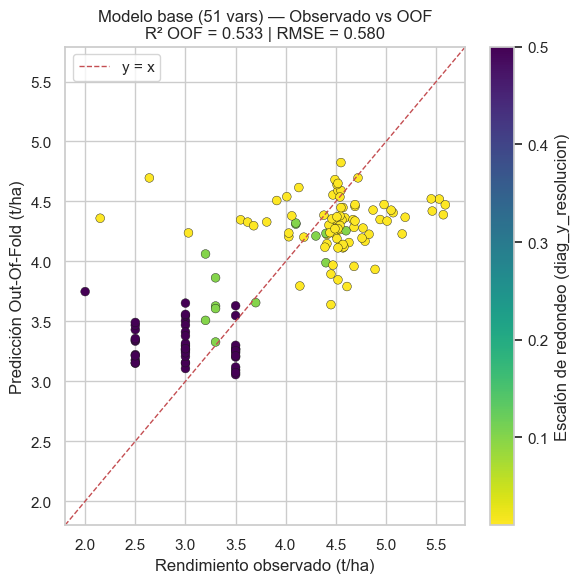

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
sc = ax.scatter(y_train, y_oof_50vars, c=res_train, cmap='viridis_r', s=40, edgecolor='k', lw=0.3)
lims = [min(y_train.min(), y_oof_50vars.min()) - 0.2, max(y_train.max(), y_oof_50vars.max()) + 0.2]
ax.plot(lims, lims, 'r--', lw=1, label='y = x')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Rendimiento observado (t/ha)')
ax.set_ylabel('Predicción Out-Of-Fold (t/ha)')
ax.set_title(f'Modelo base ({N_VARS} vars) — Observado vs OOF\n'
             f"R² OOF = {metricas_50vars.loc['Simple', 'R2']:.3f} | "
             f"RMSE = {metricas_50vars.loc['Simple', 'RMSE']:.3f}")
plt.colorbar(sc, ax=ax, label='Escalón de redondeo (diag_y_resolucion)')
ax.legend()
plt.tight_layout(); plt.show()

## 3. Interpretabilidad: Feature Importance nativa y valores SHAP

Todo se calcula sobre `modelo_50vars` (entrenado con las 138 observaciones y `sample_weight=w_train`, el esquema elegido en 2.1).

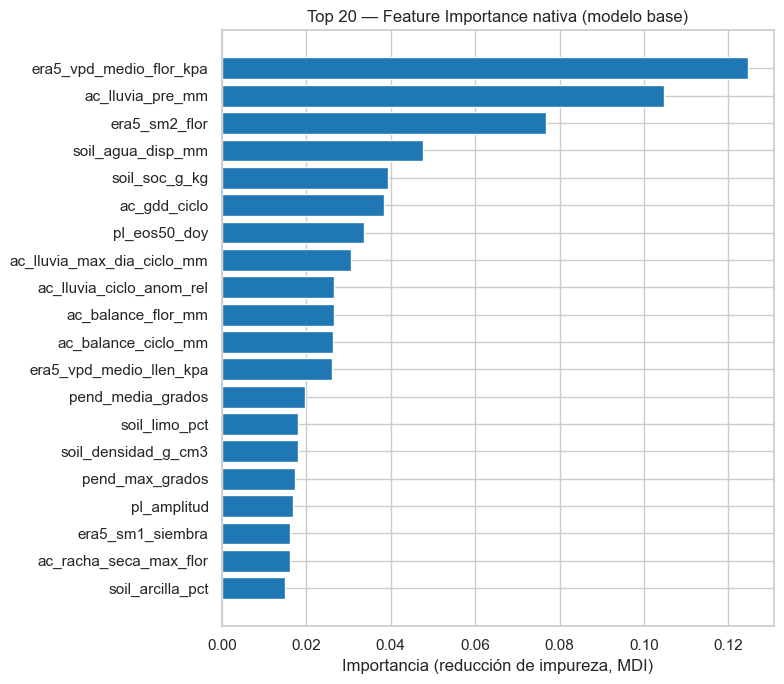

In [11]:
fi = (pd.Series(modelo_50vars.feature_importances_, index=cols_predictoras, name='importancia')
        .sort_values(ascending=False))
fi_rank = pd.Series(np.arange(1, N_VARS + 1), index=fi.index, name='rank_fi')

top20_fi = fi.head(20)
fig, ax = plt.subplots(figsize=(8, 7))
colores = ['tab:red' if c == 'diag_topo_pocos_pix' else 'tab:blue' for c in top20_fi.index]
ax.barh(top20_fi.index[::-1], top20_fi.values[::-1], color=colores[::-1])
ax.set_xlabel('Importancia (reducción de impureza, MDI)')
ax.set_title('Top 20 — Feature Importance nativa (modelo base)')
plt.tight_layout(); plt.show()

In [12]:
explainer   = shap.TreeExplainer(modelo_50vars)
shap_values = explainer.shap_values(X_train)
print(f'Matriz SHAP: {shap_values.shape} | valor esperado: {np.ravel(explainer.expected_value)[0]:.4f}')

shap_importance = (pd.Series(np.abs(shap_values).mean(axis=0), index=cols_predictoras,
                             name='mean_abs_shap')
                     .sort_values(ascending=False))
shap_rank = pd.Series(np.arange(1, N_VARS + 1), index=shap_importance.index, name='rank_shap')

Matriz SHAP: (138, 51) | valor esperado: 3.9519


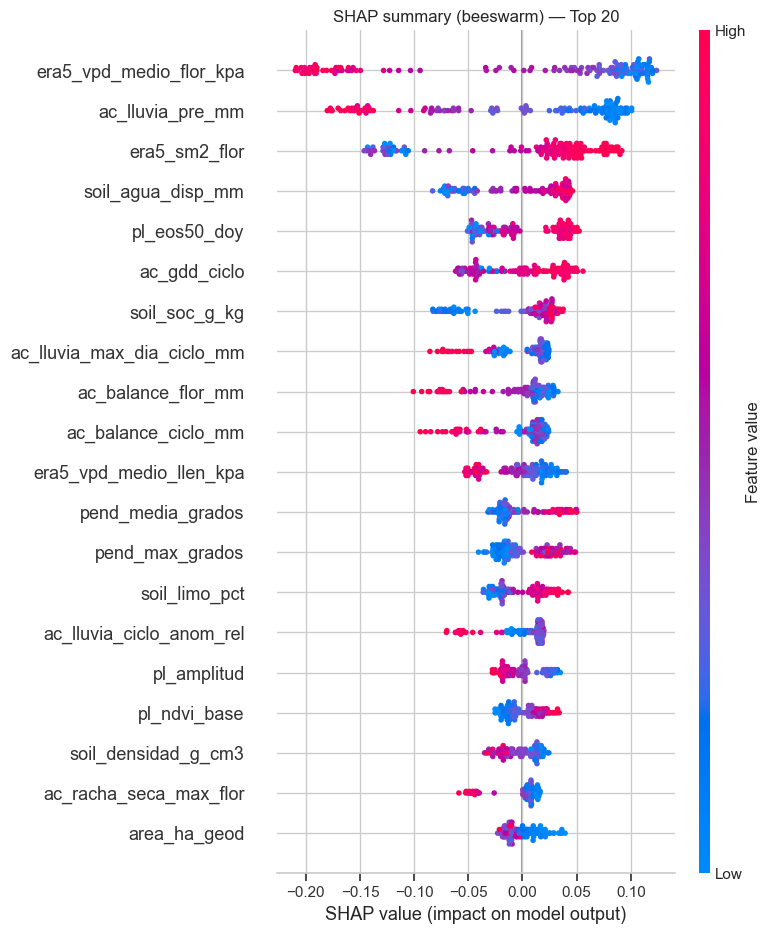

In [13]:
shap.summary_plot(shap_values, X_train, max_display=20, show=False)
plt.title('SHAP summary (beeswarm) — Top 20')
plt.tight_layout(); plt.show()

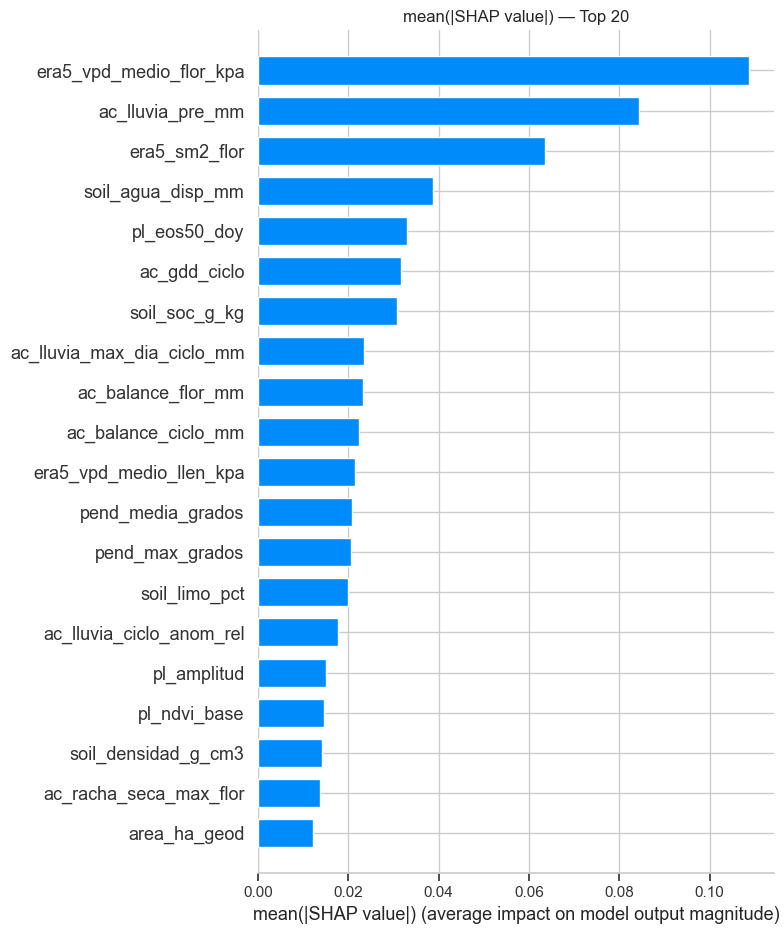

In [14]:
shap.summary_plot(shap_values, X_train, plot_type='bar', max_display=20, show=False)
plt.title('mean(|SHAP value|) — Top 20')
plt.tight_layout(); plt.show()

### 3.1 Variable de control `diag_topo_pocos_pix`

`diag_topo_pocos_pix` es un indicador de diagnóstico (polígonos con pocos píxeles topográficos). Si el modelo lo usa mucho, parte de lo que predice se debe a la calidad del dato y no a la agronomía. La celda siguiente calcula su posición en ambos rankings, la dirección de su efecto (SHAP medio por nivel y correlación entre el valor y su SHAP) y redacta la conclusión en Markdown con los valores obtenidos.

In [15]:
from IPython.display import Markdown

var_ctrl = 'diag_topo_pocos_pix'
j = cols_predictoras.index(var_ctrl)
sv_ctrl, x_ctrl = shap_values[:, j], X_train[var_ctrl].values

rk_fi, rk_shap = int(fi_rank[var_ctrl]), int(shap_rank[var_ctrl])
pct_fi   = fi[var_ctrl] / fi.sum() * 100
pct_shap = shap_importance[var_ctrl] / shap_importance.sum() * 100

efecto_nivel = (pd.DataFrame({var_ctrl: x_ctrl, 'shap': sv_ctrl})
                  .groupby(var_ctrl)['shap'].agg(['count', 'mean', 'min', 'max']))
corr = np.corrcoef(x_ctrl, sv_ctrl)[0, 1] if np.std(x_ctrl) > 0 and np.std(sv_ctrl) > 0 else np.nan

print(f'Variable de control: {var_ctrl}')
print(f'  Ranking Feature Importance : {rk_fi}/{N_VARS}  (importancia = {fi[var_ctrl]:.5f}, {pct_fi:.2f}% del total)')
print(f'  Ranking SHAP mean(|SHAP|)  : {rk_shap}/{N_VARS}  (mean|SHAP| = {shap_importance[var_ctrl]:.5f} t/ha, {pct_shap:.2f}% del total)')
print(f'  Correlación valor vs SHAP  : {corr:.3f}')
print('  SHAP medio por nivel de la variable:')
print(efecto_nivel.round(4).to_string())

if np.isnan(corr) or abs(corr) < 0.1:
    direccion = 'sin una dirección de efecto clara'
elif corr > 0:
    direccion = ('con efecto **positivo**: los polígonos marcados con pocos píxeles topográficos '
                 'reciben, en promedio, una predicción de rendimiento **mayor**')
else:
    direccion = ('con efecto **negativo**: los polígonos marcados con pocos píxeles topográficos '
                 'reciben, en promedio, una predicción de rendimiento **menor**')

if max(rk_fi, rk_shap) <= 10:
    lectura = ('Está entre las 10 variables más influyentes, así que el modelo depende en buena medida de un '
               'indicador de calidad del dato. Conviene revisar si capta un sesgo de los datos (p. ej. polígonos '
               'pequeños concentrados en un grupo de rendimiento) más que un efecto agronómico.')
elif min(rk_fi, rk_shap) <= 25:
    lectura = ('Tiene una influencia intermedia: participa en el modelo sin dominarlo. Su papel como control '
               'es razonable, pero conviene vigilar que no gane peso en el modelo reducido.')
else:
    lectura = ('Su influencia es marginal: el modelo apenas la usa, así que la calidad topográfica de los '
               'polígonos no está condicionando las predicciones.')

tabla_niveles = '\n'.join(f'| {int(n)} | {r["count"]:.0f} | {r["mean"]:+.4f} |'
                          for n, r in efecto_nivel.iterrows())
display(Markdown(f'''
#### Análisis de `{var_ctrl}`

- **Feature Importance nativa:** puesto **{rk_fi} de {N_VARS}** ({pct_fi:.2f}% de la importancia total).
- **SHAP (mean |SHAP|):** puesto **{rk_shap} de {N_VARS}** ({shap_importance[var_ctrl]:.4f} t/ha; {pct_shap:.2f}% del total).
- **Dirección del efecto:** correlación valor–SHAP = {corr:.3f}, {direccion}.

| Nivel | n | SHAP medio (t/ha) |
|---|---|---|
{tabla_niveles}

**Lectura:** {lectura}
'''))

Variable de control: diag_topo_pocos_pix
  Ranking Feature Importance : 49/51  (importancia = 0.00152, 0.15% del total)
  Ranking SHAP mean(|SHAP|)  : 41/51  (mean|SHAP| = 0.00367 t/ha, 0.46% del total)
  Correlación valor vs SHAP  : 0.955
  SHAP medio por nivel de la variable:
                     count    mean     min     max
diag_topo_pocos_pix                               
0                       86 -0.0032 -0.0057 -0.0012
1                       52  0.0044  0.0017  0.0069



#### Análisis de `diag_topo_pocos_pix`

- **Feature Importance nativa:** puesto **49 de 51** (0.15% de la importancia total).
- **SHAP (mean |SHAP|):** puesto **41 de 51** (0.0037 t/ha; 0.46% del total).
- **Dirección del efecto:** correlación valor–SHAP = 0.955, con efecto **positivo**: los polígonos marcados con pocos píxeles topográficos reciben, en promedio, una predicción de rendimiento **mayor**.

| Nivel | n | SHAP medio (t/ha) |
|---|---|---|
| 0 | 86 | -0.0032 |
| 1 | 52 | +0.0044 |

**Lectura:** Su influencia es marginal: el modelo apenas la usa, así que la calidad topográfica de los polígonos no está condicionando las predicciones.


## 4. Selección óptima de variables — Curva Top-K por SHAP

Se ordenan las variables por `mean(|SHAP|)` y se evalúan subconjuntos con las *K* mejores, siempre con los mismos `rf_params`, los mismos `splits` y `sample_weight=w_tr` en cada `.fit()`. El `K_optimo` es el que minimiza el RMSE Out-Of-Fold, restringido a *K* menor que el total de variables.

> Nota metodológica: el ranking SHAP sale del modelo entrenado con las 138 observaciones, así que el RMSE de la curva es ligeramente optimista. La comparación entre valores de *K* sigue siendo válida porque todos comparten el mismo sesgo.

In [16]:
ranking_shap = shap_importance.index.tolist()
K_list = [k for k in [5, 8, 10, 12, 15, 18, 20, 25, 30, 35, 40, 45, 50] if k < N_VARS] + [N_VARS]

resultados_k = []
for K in K_list:
    vars_k = ranking_shap[:K]
    y_oof_k, _ = cv_ponderada(X_train[vars_k], y_train, w_train, splits, verbose=False)
    m = calcular_metricas(y_train, y_oof_k)
    m_w = calcular_metricas(y_train, y_oof_k, w_eval)
    resultados_k.append({'K': K, 'RMSE_OOF': m['RMSE'], 'R2_OOF': m['R2'],
                         'MAE_OOF': m['MAE'], 'RMSE_OOF_pond': m_w['RMSE']})
    print(f'K = {K:2d} | RMSE OOF = {m["RMSE"]:.4f} | R² OOF = {m["R2"]:.4f}')

df_curva = pd.DataFrame(resultados_k).set_index('K')

K =  5 | RMSE OOF = 0.6047 | R² OOF = 0.4917


K =  8 | RMSE OOF = 0.5898 | R² OOF = 0.5163


K = 10 | RMSE OOF = 0.5654 | R² OOF = 0.5555


K = 12 | RMSE OOF = 0.5579 | R² OOF = 0.5672


K = 15 | RMSE OOF = 0.5599 | R² OOF = 0.5641


...

K = 35 | RMSE OOF = 0.5744 | R² OOF = 0.5412


K = 40 | RMSE OOF = 0.5757 | R² OOF = 0.5392


K = 45 | RMSE OOF = 0.5782 | R² OOF = 0.5352


K = 50 | RMSE OOF = 0.5841 | R² OOF = 0.5256


K = 51 | RMSE OOF = 0.5795 | R² OOF = 0.5331


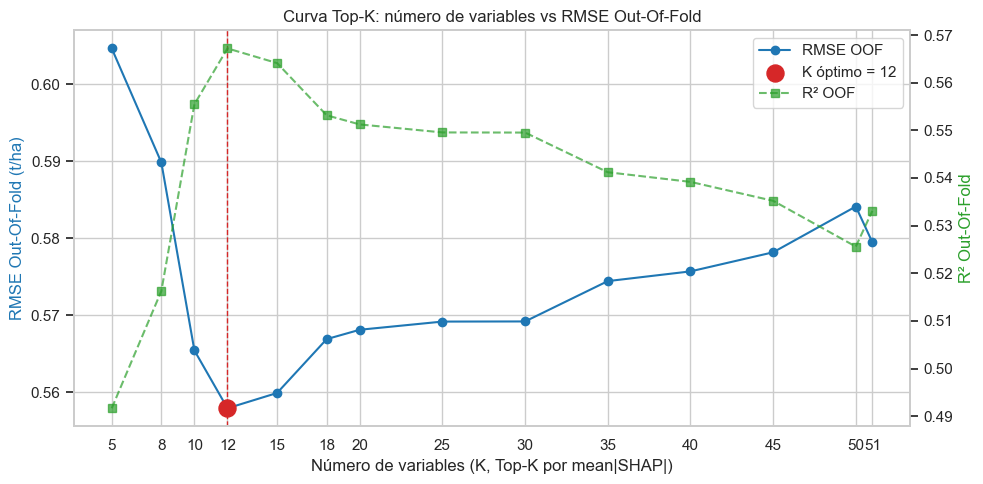

,RMSE_OOF,R2_OOF,MAE_OOF,RMSE_OOF_pond
K,,,,
5,0.6047,0.4917,0.4497,0.6139
8,0.5898,0.5163,0.4407,0.6031
10,0.5654,0.5555,0.4311,0.5813
12,0.5579,0.5672,0.4314,0.5717
15,0.5599,0.5641,0.4332,0.5723
18,0.5669,0.5532,0.4356,0.5808
20,0.5681,0.5512,0.4371,0.5787
25,0.5692,0.5496,0.4405,0.5792
30,0.5692,0.5495,0.4395,0.5808



K_optimo = 12  (RMSE OOF = 0.5579 vs 0.5795 con 51 variables)

Variables seleccionadas (12):
   1. era5_vpd_medio_flor_kpa        mean|SHAP| = 0.10881
   2. ac_lluvia_pre_mm               mean|SHAP| = 0.08431
   3. era5_sm2_flor                  mean|SHAP| = 0.06362
   4. soil_agua_disp_mm              mean|SHAP| = 0.03878
   5. pl_eos50_doy                   mean|SHAP| = 0.03302
   6. ac_gdd_ciclo                   mean|SHAP| = 0.03176
   7. soil_soc_g_kg                  mean|SHAP| = 0.03081
   8. ac_lluvia_max_dia_ciclo_mm     mean|SHAP| = 0.02352
   9. ac_balance_flor_mm             mean|SHAP| = 0.02321
  10. ac_balance_ciclo_mm            mean|SHAP| = 0.02234
  11. era5_vpd_medio_llen_kpa        mean|SHAP| = 0.02151
  12. pend_media_grados              mean|SHAP| = 0.02087

¿'diag_topo_pocos_pix' entra al modelo reducido? False


In [17]:
candidatos = df_curva[df_curva.index < N_VARS]
K_optimo = int(candidatos['RMSE_OOF'].idxmin())
vars_reducido = ranking_shap[:K_optimo]

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(df_curva.index, df_curva['RMSE_OOF'], 'o-', color='tab:blue', label='RMSE OOF')
ax1.axvline(K_optimo, color='tab:red', ls='--', lw=1)
ax1.scatter([K_optimo], [df_curva.loc[K_optimo, 'RMSE_OOF']], s=150, color='tab:red', zorder=5,
            label=f'K óptimo = {K_optimo}')
ax1.set_xlabel('Número de variables (K, Top-K por mean|SHAP|)')
ax1.set_ylabel('RMSE Out-Of-Fold (t/ha)', color='tab:blue')
ax1.set_xticks(df_curva.index)

ax2 = ax1.twinx()
ax2.plot(df_curva.index, df_curva['R2_OOF'], 's--', color='tab:green', alpha=0.7, label='R² OOF')
ax2.set_ylabel('R² Out-Of-Fold', color='tab:green')
ax2.grid(False)

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper right')
ax1.set_title('Curva Top-K: número de variables vs RMSE Out-Of-Fold')
plt.tight_layout(); plt.show()

display(df_curva.round(4))
print(f'\nK_optimo = {K_optimo}  (RMSE OOF = {df_curva.loc[K_optimo, "RMSE_OOF"]:.4f} vs '
      f'{df_curva.loc[N_VARS, "RMSE_OOF"]:.4f} con {N_VARS} variables)')
print(f'\nVariables seleccionadas ({K_optimo}):')
for i, v in enumerate(vars_reducido, 1):
    print(f'  {i:2d}. {v:30s} mean|SHAP| = {shap_importance[v]:.5f}')
print(f"\n¿'diag_topo_pocos_pix' entra al modelo reducido? {'diag_topo_pocos_pix' in vars_reducido}")

## 5. Modelo reducido (`K_optimo` variables) y comparación

In [18]:
X_train_red = X_train[vars_reducido]
X_pred_red  = X_pred[vars_reducido]

y_oof_reducido, folds_reducido = cv_ponderada(X_train_red, y_train, w_train, splits)
metricas_reducido = resumen_cv(y_train, y_oof_reducido, w_eval, folds_reducido,
                               f'Modelo reducido ({K_optimo} variables)')

,RMSE_train,MAE_train,MAPE_train,R2_train,RMSE_val,MAE_val,MAPE_val,R2_val
pliegue,,,,,,,,
1,0.4308,0.3243,9.3575,0.7411,0.4477,0.3421,9.0695,0.7250
2,0.3894,0.3038,8.4066,0.7760,0.6800,0.5034,15.8905,0.4611
3,0.4169,0.3063,8.8811,0.7769,0.4879,0.4048,10.9527,0.5074
4,0.4011,0.2995,8.4791,0.7681,0.6571,0.4978,14.2237,0.4710
5,0.4269,0.3129,8.9414,0.7495,0.4744,0.4106,11.1911,0.6689


=== Modelo reducido (12 variables) | Métricas globales Out-Of-Fold (n=138) ===


,RMSE,MAE,MAPE,R2
Simple,0.5579,0.4314,12.2591,0.5672
Ponderada (precisión),0.5717,0.4402,11.8326,0.4808


=== Modelo reducido (12 variables) | Promedio de los 5 pliegues: entrenamiento vs validación ===


,Entrenamiento (media ± sd),Validación (media ± sd),Brecha (val - train)
Métrica,,,
RMSE,0.4130 ± 0.0175,0.5494 ± 0.1100,0.1364
MAE,0.3094 ± 0.0097,0.4317 ± 0.0684,0.1224
MAPE,8.8131 ± 0.3855,12.2655 ± 2.7417,3.4524
R2,0.7623 ± 0.0162,0.5667 ± 0.1218,-0.1957


In [19]:
filas = []
for tipo in ['Simple', 'Ponderada (precisión)']:
    for m in ['RMSE', 'MAE', 'MAPE', 'R2']:
        a, b = metricas_50vars.loc[tipo, m], metricas_reducido.loc[tipo, m]
        mejor = (b > a) if m == 'R2' else (b < a)
        filas.append({'Tipo': tipo, 'Métrica': m if m != 'MAPE' else 'MAPE (%)',
                      f'RF línea base ({N_VARS} vars)': round(a, 4),
                      f'Reducido ({K_optimo} vars)': round(b, 4),
                      'Cambio absoluto': round(b - a, 4),
                      'Cambio %': round((b - a) / abs(a) * 100, 2),
                      'Mejora': '✔' if mejor else '✘'})
tabla_comp = pd.DataFrame(filas).set_index(['Tipo', 'Métrica'])
print(f'=== Comparación Out-Of-Fold: RF línea base ({N_VARS} variables) vs Modelo reducido ({K_optimo} variables) ===')
display(tabla_comp)

=== Comparación Out-Of-Fold: RF línea base (51 variables) vs Modelo reducido (12 variables) ===


RF línea base (51 vars)  Reducido (12 vars)  Cambio absoluto  Cambio % Mejora
Tipo                  Métrica                                                                       
Simple                RMSE              0.5797              0.5579          -0.0218     -3.76      ✔
                      MAE               0.4522              0.4314          -0.0208     -4.59      ✔
                      MAPE (%)         12.9327             12.2591          -0.6736     -5.21      ✔
                      R2                0.5327              0.5672           0.0345      6.48      ✔
Ponderada (precisión) RMSE              0.5897              0.5717          -0.0181     -3.07      ✔
                      MAE               0.4557              0.4402          -0.0155     -3.40      ✔
                      MAPE (%)         12.2956             11.8326          -0.4629     -3.77      ✔
                      R2                0.4475              0.4808           0.0334      7.46      ✔

In [20]:
modelo_reducido = RandomForestRegressor(**rf_params)
modelo_reducido.fit(X_train_red, y_train, sample_weight=w_train)

y_pred_reducido = modelo_reducido.predict(X_pred_red)
print(f'Predicciones del modelo reducido sobre df_pred: {len(y_pred_reducido)}')
display(pd.DataFrame({'y_pred_50vars': y_pred_50vars, 'y_pred_reducido': y_pred_reducido})
          .describe().round(3).T)
print(f'Correlación entre ambas predicciones: {np.corrcoef(y_pred_50vars, y_pred_reducido)[0, 1]:.4f}')

Predicciones del modelo reducido sobre df_pred: 59


,count,mean,std,min,25%,50%,75%,max
y_pred_50vars,59.0,3.933,0.507,3.034,3.461,4.146,4.270,4.718
y_pred_reducido,59.0,3.940,0.563,2.998,3.417,4.197,4.354,4.766


Correlación entre ambas predicciones: 0.9880


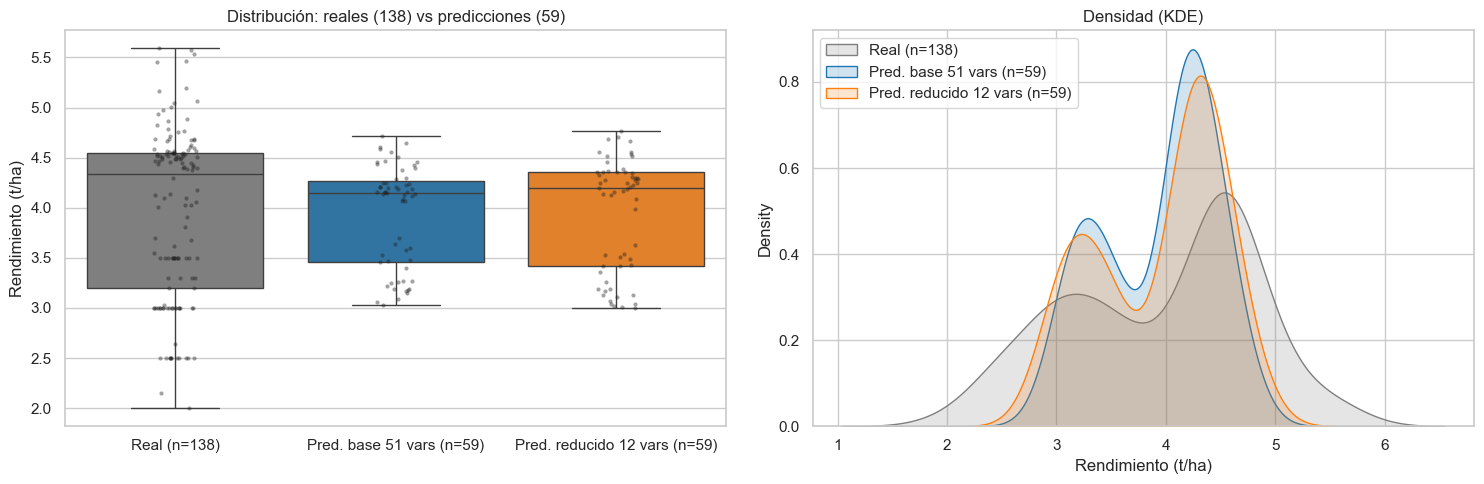

In [21]:
df_dist = pd.concat([
    pd.DataFrame({'rendimiento': y_train.values, 'serie': f'Real (n={len(y_train)})'}),
    pd.DataFrame({'rendimiento': y_pred_50vars, 'serie': f'Pred. base {N_VARS} vars (n={len(y_pred_50vars)})'}),
    pd.DataFrame({'rendimiento': y_pred_reducido, 'serie': f'Pred. reducido {K_optimo} vars (n={len(y_pred_reducido)})'}),
], ignore_index=True)
paleta = dict(zip(df_dist['serie'].unique(), ['tab:gray', 'tab:blue', 'tab:orange']))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df_dist, x='serie', y='rendimiento', hue='serie', palette=paleta, legend=False, ax=axes[0])
sns.stripplot(data=df_dist, x='serie', y='rendimiento', color='k', size=3, alpha=0.4, ax=axes[0])
axes[0].set_xlabel(''); axes[0].set_ylabel('Rendimiento (t/ha)')
axes[0].set_title('Distribución: reales (138) vs predicciones (59)')

for serie, g in df_dist.groupby('serie', sort=False):
    sns.kdeplot(g['rendimiento'], label=serie, color=paleta[serie], fill=True, alpha=0.2, ax=axes[1])
axes[1].set_xlabel('Rendimiento (t/ha)')
axes[1].set_title('Densidad (KDE)')
axes[1].legend()
plt.tight_layout(); plt.show()

## 6. Reconstrucción intermedia (RF) — sin exportar

> **Nota:** esta sección ya **no escribe en disco**. El modelo final adoptado es el **SVR de 12 variables** y la exportación definitiva de los dos CSV se hace en la **Sección 8**, al cierre del notebook. Así, un "Run All" no sobreescribe los archivos con el RF antes de llegar al SVR.

Aquí se reconstruyen en memoria las 197 filas con las predicciones del RF (base y reducido), respetando el orden original de `df`, como control intermedio.

In [22]:
pred_50  = pd.concat([pd.Series(y_oof_50vars,    index=df_train.index),
                      pd.Series(y_pred_50vars,   index=df_pred.index)])
pred_red = pd.concat([pd.Series(y_oof_reducido,  index=df_train.index),
                      pd.Series(y_pred_reducido, index=df_pred.index)])

# 1) Comparación de rendimientos
df_comparacion = df[['id_poligono', 'estado', 'municipio', 'conjunto']].copy()
df_comparacion['rendimiento_t_ha'] = df[col_target].where(df['conjunto'] == 'ENTRENAMIENTO')
df_comparacion['rendimiento_pred_50vars']   = pred_50.reindex(df.index)
df_comparacion['rendimiento_pred_reducido'] = pred_red.reindex(df.index)
df_comparacion = df_comparacion[['id_poligono', 'estado', 'municipio', 'conjunto', 'rendimiento_t_ha',
                                 'rendimiento_pred_50vars', 'rendimiento_pred_reducido']]

# 2) Rendimientos estimados (real en entrenamiento + modelo reducido en predicción)
df_estimados = df[['id_poligono', 'estado', 'municipio', 'conjunto']].copy()
df_estimados['rendimiento_t_ha'] = df[col_target].where(df['conjunto'] == 'ENTRENAMIENTO',
                                                        pred_red.reindex(df.index))

ruta_comp = DATA_DIR / 'dataset_comparacion_rendimientos.csv'
ruta_est  = DATA_DIR / 'dataset_rendimientos_estimados_svr12.csv'
# Exportación desactivada: los CSV definitivos (modelo final SVR) se escriben en la Sección 8.
print('Sección 6: DataFrames intermedios del RF construidos en memoria (sin exportar).')

Sección 6: DataFrames intermedios del RF construidos en memoria (sin exportar).


In [23]:
# Verificación en memoria de los DataFrames intermedios del RF (no se leen ni escriben archivos)
comp = df_comparacion.reset_index(drop=True)
est  = df_estimados.reset_index(drop=True)

for nombre, d in [('df_comparacion (RF, en memoria)', comp), ('df_estimados (RF, en memoria)', est)]:
    print('=' * 90)
    print(f'{nombre} | shape = {d.shape}')
    display(d.head())
    print('NaN por columna:')
    print(d.isna().sum().to_string())
    print(f"Filas por conjunto: {d['conjunto'].value_counts().to_dict()}")

# Comprobaciones de integridad
es_tr_c, es_tr_e = comp['conjunto'] == 'ENTRENAMIENTO', est['conjunto'] == 'ENTRENAMIENTO'
assert comp.shape == (197, 7) and est.shape == (197, 5)
assert (comp['id_poligono'].values == df['id_poligono'].values).all()
assert (est['id_poligono'].values == df['id_poligono'].values).all()
assert comp.loc[es_tr_c, 'rendimiento_t_ha'].notna().all() and comp.loc[~es_tr_c, 'rendimiento_t_ha'].isna().all()
assert comp[['rendimiento_pred_50vars', 'rendimiento_pred_reducido']].notna().all().all()
assert est['rendimiento_t_ha'].notna().all()
assert np.allclose(est.loc[es_tr_e, 'rendimiento_t_ha'], df_train[col_target].values)
assert np.allclose(est.loc[~es_tr_e, 'rendimiento_t_ha'], y_pred_reducido)
print('=' * 90)
print('✔ Verificación intermedia (RF) completa: 197 filas, orden original y reglas de llenado correctas.')

df_comparacion (RF, en memoria) | shape = (197, 7)


,id_poligono,estado,municipio,conjunto,rendimiento_t_ha,rendimiento_pred_50vars,rendimiento_pred_reducido
0,AGC_001,Tlaxcala,Calpulalpan,ENTRENAMIENTO,3.50,3.202254,3.090676
1,AGC_002,Puebla,Chignahuapan,ENTRENAMIENTO,4.63,4.157066,4.241730
2,AGC_003,Hidalgo,Singuilucan,PREDICCION,NaN,3.701611,3.510935
3,AGC_004,Tlaxcala,Calpulalpan,ENTRENAMIENTO,3.00,3.149588,3.118083
4,AGC_005,Puebla,Chignahuapan,ENTRENAMIENTO,5.16,4.228840,4.369097


NaN por columna:
id_poligono                   0
estado                        0
municipio                     0
conjunto                      0
rendimiento_t_ha             59
rendimiento_pred_50vars       0
rendimiento_pred_reducido     0
Filas por conjunto: {'ENTRENAMIENTO': 138, 'PREDICCION': 59}
df_estimados (RF, en memoria) | shape = (197, 5)


,id_poligono,estado,municipio,conjunto,rendimiento_t_ha
0,AGC_001,Tlaxcala,Calpulalpan,ENTRENAMIENTO,3.500000
1,AGC_002,Puebla,Chignahuapan,ENTRENAMIENTO,4.630000
2,AGC_003,Hidalgo,Singuilucan,PREDICCION,3.510935
3,AGC_004,Tlaxcala,Calpulalpan,ENTRENAMIENTO,3.000000
4,AGC_005,Puebla,Chignahuapan,ENTRENAMIENTO,5.160000


NaN por columna:
id_poligono         0
estado              0
municipio           0
conjunto            0
rendimiento_t_ha    0
Filas por conjunto: {'ENTRENAMIENTO': 138, 'PREDICCION': 59}
✔ Verificación intermedia (RF) completa: 197 filas, orden original y reglas de llenado correctas.


## 7. Torneo de Algoritmos sobre el Subconjunto Óptimo (12 variables)

Todos los modelos usan **las mismas `K_optimo` variables** (`vars_reducido`), las 138 observaciones de entrenamiento y **los mismos 5 `splits`**. Se evalúan con predicciones Out-Of-Fold (`cross_val_predict`). La referencia es el Random Forest reducido (sección 5).

- **Árboles:** RandomForest (referencia) y ExtraTrees con los mismos hiperparámetros.
- **Boosting para *small data*:** `HistGradientBoostingRegressor` y `XGBRegressor` (árboles poco profundos, *learning rate* bajo, regularización L2). LightGBM no está instalado en el entorno.
- **Lineal:** `StandardScaler` + `ElasticNetCV` (`l1_ratio` en [0.1, 0.5, 0.7, 0.9, 1.0]).
- **Kernel:** `StandardScaler` + `SVR(rbf)`.
- **Ensamble:** `VotingRegressor` con los 3 mejores modelos individuales según el RMSE OOF.

Esta sección no modifica variables previas ni vuelve a exportar los CSV.

In [24]:
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, VotingRegressor
from sklearn.linear_model import ElasticNetCV
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
from xgboost import XGBRegressor

X_torneo = X_train[vars_reducido]
print(f'Variables del torneo ({len(vars_reducido)}): {vars_reducido}')

# El esquema de pesos elegido en 2.1 es uniforme (sin sample_weight), así que
# cross_val_predict sin pesos reproduce exactamente al RF reducido de la sección 5.
assert np.allclose(w_train, 1.0), 'w_train no es uniforme: habría que pasar sample_weight al torneo'

modelos_torneo = {
    'Random Forest Reducido (referencia)': RandomForestRegressor(**rf_params),
    'ExtraTrees': ExtraTreesRegressor(n_estimators=300, max_depth=5, min_samples_leaf=4,
                                      max_features='sqrt', random_state=42, n_jobs=-1),
    'HistGradientBoosting (small data)': HistGradientBoostingRegressor(
        max_depth=3, min_samples_leaf=5, learning_rate=0.03, max_iter=150,
        l2_regularization=1.0, random_state=42),
    'XGBoost (small data)': XGBRegressor(
        max_depth=3, min_child_weight=5, learning_rate=0.03, n_estimators=150,
        reg_lambda=1.0, random_state=42, n_jobs=-1, verbosity=0),
    'StandardScaler + ElasticNetCV': make_pipeline(
        StandardScaler(), ElasticNetCV(l1_ratio=[0.1, 0.5, 0.7, 0.9, 1.0], max_iter=20000)),
    'StandardScaler + SVR (rbf)': make_pipeline(
        StandardScaler(), SVR(kernel='rbf', C=1.0, epsilon=0.1)),
}

oof_torneo, filas = {}, []
for nombre, modelo in modelos_torneo.items():
    oof_torneo[nombre] = cross_val_predict(modelo, X_torneo, y_train, cv=splits, n_jobs=1)
    m = calcular_metricas(y_train, oof_torneo[nombre])
    filas.append({'Modelo': nombre, **m})
    print(f'{nombre:38s} RMSE = {m["RMSE"]:.4f} | R² = {m["R2"]:.4f}')

# Control: la referencia debe coincidir con y_oof_reducido de la sección 5
assert np.allclose(oof_torneo['Random Forest Reducido (referencia)'], y_oof_reducido)
print('\n✔ La referencia reproduce exactamente las predicciones OOF del RF reducido.')

Variables del torneo (12): ['era5_vpd_medio_flor_kpa', 'ac_lluvia_pre_mm', 'era5_sm2_flor', 'soil_agua_disp_mm', 'pl_eos50_doy', 'ac_gdd_ciclo', 'soil_soc_g_kg', 'ac_lluvia_max_dia_ciclo_mm', 'ac_balance_flor_mm', 'ac_balance_ciclo_mm', 'era5_vpd_medio_llen_kpa', 'pend_media_grados']


Random Forest Reducido (referencia)    RMSE = 0.5579 | R² = 0.5672


ExtraTrees                             RMSE = 0.5623 | R² = 0.5603


HistGradientBoosting (small data)      RMSE = 0.5573 | R² = 0.5682


XGBoost (small data)                   RMSE = 0.5531 | R² = 0.5746


StandardScaler + ElasticNetCV          RMSE = 0.5689 | R² = 0.5499
StandardScaler + SVR (rbf)             RMSE = 0.5314 | R² = 0.6073

✔ La referencia reproduce exactamente las predicciones OOF del RF reducido.


In [25]:
# Ensamble: VotingRegressor con los 3 mejores modelos individuales (menor RMSE OOF)
ranking_indiv = pd.DataFrame(filas).sort_values('RMSE')
top3 = ranking_indiv['Modelo'].head(3).tolist()
print('Modelos del VotingRegressor:', top3)

voting = VotingRegressor([(f'm{i}', clone(modelos_torneo[n])) for i, n in enumerate(top3, 1)])
nombre_voting = 'VotingRegressor (' + ' + '.join(top3) + ')'
oof_torneo[nombre_voting] = cross_val_predict(voting, X_torneo, y_train, cv=splits, n_jobs=1)
filas.append({'Modelo': nombre_voting, **calcular_metricas(y_train, oof_torneo[nombre_voting])})

# ElasticNet: hiperparámetros elegidos (ajuste con las 138 observaciones, solo informativo)
enet = clone(modelos_torneo['StandardScaler + ElasticNetCV']).fit(X_torneo, y_train)[-1]
print(f'ElasticNetCV -> alpha = {enet.alpha_:.4f} | l1_ratio = {enet.l1_ratio_} | '
      f'coeficientes no nulos = {(enet.coef_ != 0).sum()}/{len(vars_reducido)}')

Modelos del VotingRegressor: ['StandardScaler + SVR (rbf)', 'XGBoost (small data)', 'HistGradientBoosting (small data)']


ElasticNetCV -> alpha = 0.1208 | l1_ratio = 0.1 | coeficientes no nulos = 10/12


In [26]:
ref = 'Random Forest Reducido (referencia)'
tabla_torneo = (pd.DataFrame(filas)
                  .rename(columns={'MAPE': 'MAPE (%)', 'R2': 'R²'})
                  .sort_values('RMSE').reset_index(drop=True))
rmse_ref = tabla_torneo.loc[tabla_torneo['Modelo'] == ref, 'RMSE'].item()
r2_ref   = tabla_torneo.loc[tabla_torneo['Modelo'] == ref, 'R²'].item()
tabla_torneo['ΔRMSE vs RF'] = tabla_torneo['RMSE'] - rmse_ref
tabla_torneo['¿Supera al RF?'] = np.where(tabla_torneo['Modelo'] == ref, '— referencia',
                                          np.where(tabla_torneo['RMSE'] < rmse_ref, '✔ Sí', '✘ No'))
tabla_torneo.index = tabla_torneo.index + 1

print(f'=== Torneo de algoritmos | {len(vars_reducido)} variables | OOF (n={len(y_train)}) | '
      f'Referencia: RMSE = {rmse_ref:.4f}, R² = {r2_ref:.4f} ===')
display(tabla_torneo.round(4))

ganadores = tabla_torneo[tabla_torneo['¿Supera al RF?'] == '✔ Sí']
if ganadores.empty:
    print('Ningún modelo supera al Random Forest Reducido en RMSE OOF.')
else:
    for _, r in ganadores.iterrows():
        print(f"✔ {r['Modelo']} supera al RF reducido: RMSE {r['RMSE']:.4f} ({r['ΔRMSE vs RF']:+.4f}) | "
              f"R² {r['R²']:.4f} ({r['R²'] - r2_ref:+.4f})")

=== Torneo de algoritmos | 12 variables | OOF (n=138) | Referencia: RMSE = 0.5579, R² = 0.5672 ===


,Modelo,RMSE,MAE,MAPE (%),R²,ΔRMSE vs RF,¿Supera al RF?
1,StandardScaler + SVR (rbf),0.5314,0.3861,11.1078,0.6073,-0.0265,✔ Sí
2,VotingRegressor (StandardScaler + SVR (rbf) + ...,0.5342,0.3968,11.2213,0.6033,-0.0238,✔ Sí
3,XGBoost (small data),0.5531,0.4145,11.6367,0.5746,-0.0048,✔ Sí
4,HistGradientBoosting (small data),0.5573,0.4197,11.7531,0.5682,-0.0006,✔ Sí
5,Random Forest Reducido (referencia),0.5579,0.4314,12.2591,0.5672,0.0000,— referencia
6,ExtraTrees,0.5623,0.4316,12.4466,0.5603,0.0044,✘ No
7,StandardScaler + ElasticNetCV,0.5689,0.4470,12.6178,0.5499,0.0110,✘ No


✔ StandardScaler + SVR (rbf) supera al RF reducido: RMSE 0.5314 (-0.0265) | R² 0.6073 (+0.0401)
✔ VotingRegressor (StandardScaler + SVR (rbf) + XGBoost (small data) + HistGradientBoosting (small data)) supera al RF reducido: RMSE 0.5342 (-0.0238) | R² 0.6033 (+0.0361)
✔ XGBoost (small data) supera al RF reducido: RMSE 0.5531 (-0.0048) | R² 0.5746 (+0.0074)
✔ HistGradientBoosting (small data) supera al RF reducido: RMSE 0.5573 (-0.0006) | R² 0.5682 (+0.0010)


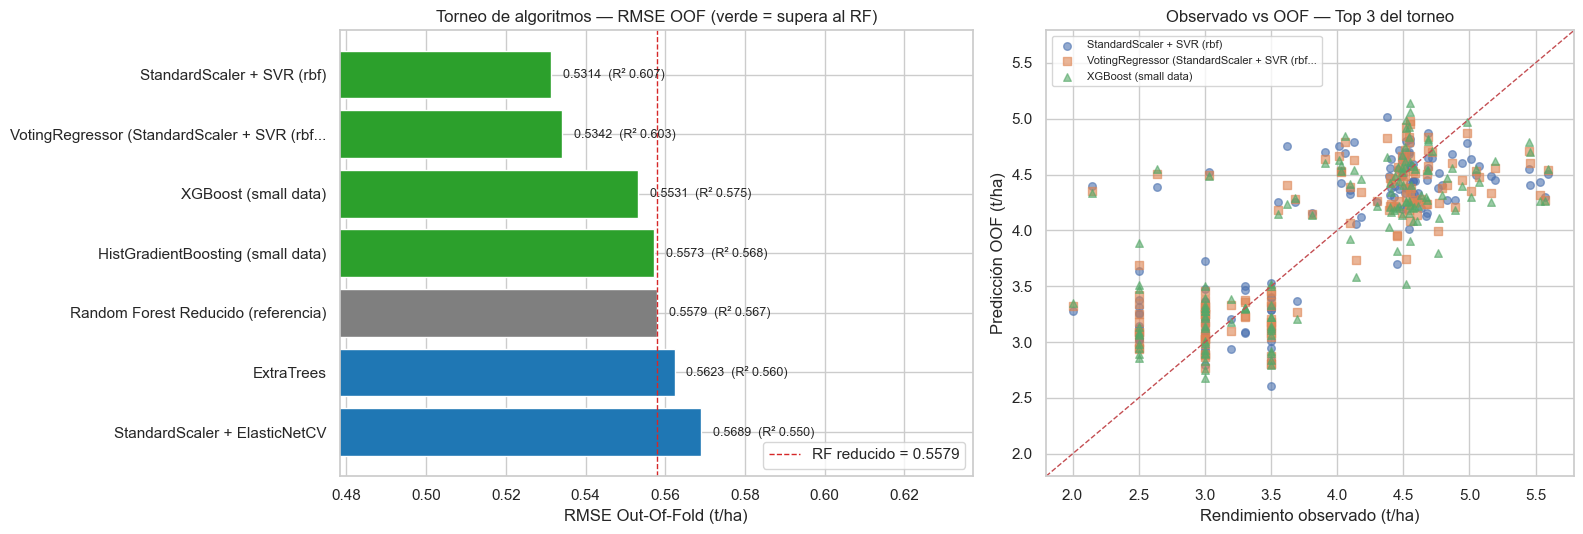

In [27]:
# Visualización: RMSE OOF por modelo y observado vs OOF de los 3 primeros
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1.2, 1]})

t = tabla_torneo.iloc[::-1]
etiquetas = [m if len(m) < 45 else m[:42] + '...' for m in t['Modelo']]
colores = ['tab:gray' if m == ref else ('tab:green' if r < rmse_ref else 'tab:blue')
           for m, r in zip(t['Modelo'], t['RMSE'])]
axes[0].barh(etiquetas, t['RMSE'], color=colores)
axes[0].axvline(rmse_ref, color='tab:red', ls='--', lw=1, label=f'RF reducido = {rmse_ref:.4f}')
for y_pos, (r, r2) in enumerate(zip(t['RMSE'], t['R²'])):
    axes[0].text(r + 0.003, y_pos, f'{r:.4f}  (R² {r2:.3f})', va='center', fontsize=9)
axes[0].set_xlim(t['RMSE'].min() * 0.9, t['RMSE'].max() * 1.12)
axes[0].set_xlabel('RMSE Out-Of-Fold (t/ha)')
axes[0].set_title('Torneo de algoritmos — RMSE OOF (verde = supera al RF)')
axes[0].legend(loc='lower right')

lims = [y_train.min() - 0.2, y_train.max() + 0.2]
for nombre, mk_ in zip(tabla_torneo['Modelo'].head(3), ['o', 's', '^']):
    axes[1].scatter(y_train, oof_torneo[nombre], marker=mk_, s=30, alpha=0.6,
                    label=nombre if len(nombre) < 45 else nombre[:42] + '...')
axes[1].plot(lims, lims, 'r--', lw=1)
axes[1].set_xlim(lims); axes[1].set_ylim(lims)
axes[1].set_xlabel('Rendimiento observado (t/ha)'); axes[1].set_ylabel('Predicción OOF (t/ha)')
axes[1].set_title('Observado vs OOF — Top 3 del torneo')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7.1 Verificación de estabilidad del SVR

El torneo usó una sola partición (`random_state=42`), y con 138 observaciones las diferencias pequeñas pueden deberse a cómo cayeron los pliegues. Para comprobarlo:

1. **Multi-semilla:** se repite la validación cruzada con 10 semillas de `StratifiedKFold` (siempre estratificando por `grupo_rend`) para los 4 mejores modelos. Se reporta media ± desviación estándar y la diferencia **pareada** SVR − RF por semilla.
2. **Micro-ajuste del SVR:**
   - Rejilla de 48 combinaciones (`C` × `epsilon` × `gamma`) evaluada sobre las mismas 10 semillas.
   - Validación cruzada **anidada** (`GridSearchCV` dentro de cada pliegue) para estimar sin sesgo el rendimiento de un SVR ajustado.
3. **Predicciones de las 59 parcelas:** comparación entre el SVR y el RF reducido.

Ninguna de estas celdas exporta archivos.

In [28]:
from sklearn.model_selection import GridSearchCV, KFold

seeds = [42, 7, 13, 21, 99, 101, 202, 303, 404, 505]
modelos_estab = {
    'StandardScaler + SVR (rbf)': modelos_torneo['StandardScaler + SVR (rbf)'],
    'VotingRegressor (top 3)':    voting,
    'XGBoost (small data)':       modelos_torneo['XGBoost (small data)'],
    'Random Forest Reducido':     modelos_torneo['Random Forest Reducido (referencia)'],
}
print('VotingRegressor =', ' + '.join(top3))

splits_por_semilla = {s: list(StratifiedKFold(n_splits=5, shuffle=True, random_state=s)
                              .split(X_torneo, df_train['grupo_rend'])) for s in seeds}

filas_estab = []
for s in seeds:
    for nombre, modelo in modelos_estab.items():
        oof = cross_val_predict(clone(modelo), X_torneo, y_train, cv=splits_por_semilla[s], n_jobs=1)
        filas_estab.append({'seed': s, 'Modelo': nombre, **calcular_metricas(y_train, oof)})
    print(f'seed {s:3d} listo')
df_estab = pd.DataFrame(filas_estab)

# Resumen media ± sd por modelo (ordenado por RMSE medio)
agg = df_estab.groupby('Modelo')[['RMSE', 'MAE', 'MAPE', 'R2']].agg(['mean', 'std'])
agg = agg.sort_values(('RMSE', 'mean'))
resumen_estab = pd.DataFrame({m: agg[(m, 'mean')].map('{:.4f}'.format) + ' ± ' + agg[(m, 'std')].map('{:.4f}'.format)
                              for m in ['RMSE', 'MAE', 'MAPE', 'R2']}).rename(columns={'MAPE': 'MAPE (%)', 'R2': 'R²'})
rank_rmse = df_estab.pivot(index='seed', columns='Modelo', values='RMSE').rank(axis=1)
resumen_estab['Veces 1.º (de 10)'] = (rank_rmse == 1).sum().reindex(resumen_estab.index)
print(f'\n=== Estabilidad multi-semilla | {len(vars_reducido)} variables | {len(seeds)} semillas x 5 pliegues ===')
display(resumen_estab)

# Diferencia pareada SVR - RF (misma partición en cada semilla)
piv = df_estab.pivot(index='seed', columns='Modelo')
d_rmse = piv[('RMSE', 'StandardScaler + SVR (rbf)')] - piv[('RMSE', 'Random Forest Reducido')]
d_r2   = piv[('R2',   'StandardScaler + SVR (rbf)')] - piv[('R2',   'Random Forest Reducido')]
print(f'Diferencia pareada SVR - RF por semilla:')
print(f'  ΔRMSE = {d_rmse.mean():+.4f} ± {d_rmse.std():.4f}  (SVR mejor en {(d_rmse < 0).sum()}/10 semillas; '
      f'rango [{d_rmse.min():+.4f}, {d_rmse.max():+.4f}])')
print(f'  ΔR²   = {d_r2.mean():+.4f} ± {d_r2.std():.4f}')

VotingRegressor = StandardScaler + SVR (rbf) + XGBoost (small data) + HistGradientBoosting (small data)


seed  42 listo


seed   7 listo


seed  13 listo


seed  21 listo


...

seed 303 listo


seed 404 listo


seed 505 listo

=== Estabilidad multi-semilla | 12 variables | 10 semillas x 5 pliegues ===


,RMSE,MAE,MAPE (%),R²,Veces 1.º (de 10)
Modelo,,,,,
StandardScaler + SVR (rbf),0.5204 ± 0.0100,0.3740 ± 0.0082,10.7309 ± 0.2671,0.6233 ± 0.0144,10
VotingRegressor (top 3),0.5375 ± 0.0140,0.3950 ± 0.0075,11.2178 ± 0.2377,0.5980 ± 0.0209,0
XGBoost (small data),0.5652 ± 0.0178,0.4210 ± 0.0114,11.8846 ± 0.3413,0.5554 ± 0.0280,0
Random Forest Reducido,0.5661 ± 0.0063,0.4332 ± 0.0056,12.3226 ± 0.1645,0.5545 ± 0.0100,0


Diferencia pareada SVR - RF por semilla:
  ΔRMSE = -0.0456 ± 0.0096  (SVR mejor en 10/10 semillas; rango [-0.0603, -0.0265])
  ΔR²   = +0.0688 ± 0.0140


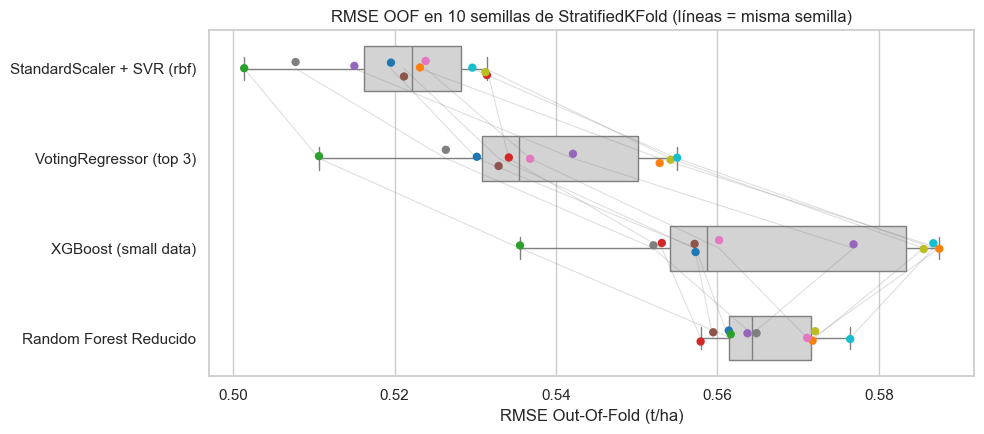

In [29]:
fig, ax = plt.subplots(figsize=(10, 4.5))
orden = resumen_estab.index.tolist()
sns.boxplot(data=df_estab, x='RMSE', y='Modelo', order=orden, color='lightgray', ax=ax, width=0.5)
sns.stripplot(data=df_estab, x='RMSE', y='Modelo', order=orden, hue='seed', palette='tab10',
              size=6, ax=ax, legend=False)
for s in seeds:   # une los puntos de una misma semilla para ver la comparación pareada
    g = df_estab[df_estab['seed'] == s].set_index('Modelo').loc[orden]
    ax.plot(g['RMSE'], range(len(orden)), color='gray', alpha=0.25, lw=0.8)
ax.set_xlabel('RMSE Out-Of-Fold (t/ha)'); ax.set_ylabel('')
ax.set_title('RMSE OOF en 10 semillas de StratifiedKFold (líneas = misma semilla)')
plt.tight_layout(); plt.show()

In [30]:
# --- Micro-ajuste del SVR: rejilla evaluada en las 10 semillas
grid_svr = {'svr__C': [0.5, 1.0, 2.0, 5.0],
            'svr__epsilon': [0.05, 0.1, 0.2],
            'svr__gamma': ['scale', 'auto', 0.05, 0.1]}
from sklearn.model_selection import ParameterGrid

svr_base = make_pipeline(StandardScaler(), SVR(kernel='rbf'))
filas_grid = []
for p in ParameterGrid(grid_svr):
    rmses, r2s = [], []
    for s in seeds:
        oof = cross_val_predict(clone(svr_base).set_params(**p), X_torneo, y_train,
                                cv=splits_por_semilla[s], n_jobs=1)
        m = calcular_metricas(y_train, oof)
        rmses.append(m['RMSE']); r2s.append(m['R2'])
    filas_grid.append({'C': p['svr__C'], 'epsilon': p['svr__epsilon'], 'gamma': p['svr__gamma'],
                       'RMSE_media': np.mean(rmses), 'RMSE_sd': np.std(rmses, ddof=1),
                       'R2_media': np.mean(r2s)})
df_grid = pd.DataFrame(filas_grid).sort_values('RMSE_media').reset_index(drop=True)
df_grid.index += 1

es_default = (df_grid['C'] == 1.0) & (df_grid['epsilon'] == 0.1) & (df_grid['gamma'] == 'scale')
pos_default = int(df_grid.index[es_default][0])
print(f'Rejilla SVR: {len(df_grid)} combinaciones x {len(seeds)} semillas')
print(f'Top 10 (media de las 10 semillas). Default (C=1.0, eps=0.1, gamma=scale) en el puesto {pos_default}:')
display(df_grid.head(10).round(4))
print('Default:')
display(df_grid[es_default].round(4))

mejor = df_grid.iloc[0]
mejora = df_grid.loc[es_default, 'RMSE_media'].item() - mejor['RMSE_media']
print(f"Mejor combinación: C={mejor['C']}, epsilon={mejor['epsilon']}, gamma={mejor['gamma']} | "
      f"RMSE medio = {mejor['RMSE_media']:.4f} (mejora de {mejora:.4f} sobre el default)")

Rejilla SVR: 48 combinaciones x 10 semillas
Top 10 (media de las 10 semillas). Default (C=1.0, eps=0.1, gamma=scale) en el puesto 13:


,C,epsilon,gamma,RMSE_media,RMSE_sd,R2_media
1,5.0,0.20,0.05,0.5155,0.0099,0.6304
2,2.0,0.20,scale,0.5163,0.0111,0.6292
3,2.0,0.20,auto,0.5163,0.0111,0.6292
4,2.0,0.10,auto,0.5174,0.0113,0.6277
5,2.0,0.10,scale,0.5174,0.0113,0.6277
6,2.0,0.20,0.1,0.5186,0.0120,0.6258
7,2.0,0.20,0.05,0.5193,0.0106,0.6248
8,2.0,0.10,0.1,0.5195,0.0121,0.6246
9,2.0,0.10,0.05,0.5201,0.0100,0.6238
10,1.0,0.05,scale,0.5201,0.0083,0.6238


Default:


,C,epsilon,gamma,RMSE_media,RMSE_sd,R2_media
13,1.0,0.1,scale,0.5204,0.01,0.6233


Mejor combinación: C=5.0, epsilon=0.2, gamma=0.05 | RMSE medio = 0.5155 (mejora de 0.0049 sobre el default)


In [31]:
# --- Validación cruzada anidada: estimación sin sesgo de un SVR con ajuste de hiperparámetros.
# Pliegue externo = splits (seed 42, igual que el torneo); pliegue interno = KFold(5) dentro de cada pliegue externo.
svr_gs = GridSearchCV(clone(svr_base), grid_svr, scoring='neg_root_mean_squared_error',
                      cv=KFold(n_splits=5, shuffle=True, random_state=42), n_jobs=-1)
oof_nested = np.full(len(y_train), np.nan)
params_por_pliegue = []
for k, (tr, va) in enumerate(splits, 1):
    gs = clone(svr_gs).fit(X_torneo.iloc[tr], y_train.iloc[tr])
    oof_nested[va] = gs.predict(X_torneo.iloc[va])
    params_por_pliegue.append({'pliegue': k, **{c.replace('svr__', ''): v for c, v in gs.best_params_.items()}})

m_nested = calcular_metricas(y_train, oof_nested)
m_default = calcular_metricas(y_train, oof_torneo['StandardScaler + SVR (rbf)'])
print('Hiperparámetros elegidos en cada pliegue externo:')
display(pd.DataFrame(params_por_pliegue).set_index('pliegue'))
display(pd.DataFrame({'SVR default (C=1, eps=0.1, scale)': m_default,
                      'SVR ajustado (CV anidada)': m_nested,
                      'RF reducido': calcular_metricas(y_train, y_oof_reducido)}).T.round(4))

# SVR final: se adopta la mejor combinación solo si mejora el RMSE medio en más de 1 sd entre semillas;
# si no, se mantienen los valores por defecto (más simples y ya validados).
umbral = df_grid.loc[es_default, 'RMSE_sd'].item()
if mejora > umbral:
    params_svr_final = {'C': mejor['C'], 'epsilon': mejor['epsilon'], 'gamma': mejor['gamma']}
    print(f'\n→ Se adopta la mejor combinación de la rejilla (mejora {mejora:.4f} > sd {umbral:.4f}).')
else:
    params_svr_final = {'C': 1.0, 'epsilon': 0.1, 'gamma': 'scale'}
    print(f'\n→ Se mantiene el SVR por defecto: la mejora de la rejilla ({mejora:.4f}) no supera la '
          f'variabilidad entre semillas (sd = {umbral:.4f}).')
print(f'params_svr_final = {params_svr_final}')

Hiperparámetros elegidos en cada pliegue externo:


,C,epsilon,gamma
pliegue,,,
1,5.0,0.20,0.05
2,2.0,0.20,0.10
3,1.0,0.05,0.05
4,2.0,0.20,0.10
5,1.0,0.05,0.05


,RMSE,MAE,MAPE,R2
"SVR default (C=1, eps=0.1, scale)",0.5314,0.3861,11.1078,0.6073
SVR ajustado (CV anidada),0.5388,0.3967,11.4435,0.5964
RF reducido,0.5579,0.4314,12.2591,0.5672



→ Se mantiene el SVR por defecto: la mejora de la rejilla (0.0049) no supera la variabilidad entre semillas (sd = 0.0100).
params_svr_final = {'C': 1.0, 'epsilon': 0.1, 'gamma': 'scale'}


In [32]:
# --- SVR final con las 138 observaciones y comparación en las 59 parcelas de predicción
svr_final = make_pipeline(StandardScaler(), SVR(kernel='rbf', **params_svr_final))
svr_final.fit(X_torneo, y_train)
y_pred_svr = svr_final.predict(X_pred[vars_reducido])

comp_59 = pd.DataFrame({'RF reducido': y_pred_reducido, 'SVR': y_pred_svr}, index=df_pred.index)
r_pearson = comp_59.corr().iloc[0, 1]
r_spearman = comp_59.corr(method='spearman').iloc[0, 1]
dif = comp_59['SVR'] - comp_59['RF reducido']

print(f'Comparación en las {len(comp_59)} parcelas de predicción')
display(comp_59.agg(['mean', 'std', 'min', 'max']).T.round(4)
               .rename(columns={'mean': 'Media', 'std': 'Desv. est.', 'min': 'Mínimo', 'max': 'Máximo'}))
print(f'Correlación Pearson = {r_pearson:.4f} | Spearman = {r_spearman:.4f}')
print(f'Diferencia SVR - RF: media = {dif.mean():+.4f} | MAE entre modelos = {dif.abs().mean():.4f} t/ha | '
      f'|dif| > 0.5 t/ha en {(dif.abs() > 0.5).sum()} parcelas')
print(f'Rango real de entrenamiento: [{y_train.min():.2f}, {y_train.max():.2f}] t/ha | '
      f'SVR fuera de rango: {((y_pred_svr < y_train.min()) | (y_pred_svr > y_train.max())).sum()} parcelas')

print('\nParcelas con mayor discrepancia entre modelos:')
top_dif = (df_pred[['id_poligono', 'estado', 'municipio']]
             .assign(pred_RF=comp_59['RF reducido'], pred_SVR=comp_59['SVR'], dif_SVR_RF=dif)
             .reindex(dif.abs().sort_values(ascending=False).index).head(8))
display(top_dif.round(3))

Comparación en las 59 parcelas de predicción


,Media,Desv. est.,Mínimo,Máximo
RF reducido,3.9395,0.5633,2.9980,4.7661
SVR,3.9622,0.6751,2.7529,4.8998


Correlación Pearson = 0.9773 | Spearman = 0.9577
Diferencia SVR - RF: media = +0.0226 | MAE entre modelos = 0.1419 t/ha | |dif| > 0.5 t/ha en 1 parcelas
Rango real de entrenamiento: [2.00, 5.59] t/ha | SVR fuera de rango: 0 parcelas

Parcelas con mayor discrepancia entre modelos:


,id_poligono,estado,municipio,pred_RF,pred_SVR,dif_SVR_RF
41,AGC_042,Hidalgo,Singuilucan,3.420,2.873,-0.547
29,AGC_030,Hidalgo,Singuilucan,3.628,3.244,-0.383
93,AGC_094,Puebla,Chignahuapan,4.361,4.717,0.356
174,AGC_175,Puebla,Chignahuapan,4.383,4.690,0.307
106,AGC_107,Hidalgo,Almoloya,4.197,4.443,0.246
49,AGC_050,Tlaxcala,Calpulalpan,2.998,2.753,-0.245
146,AGC_147,Tlaxcala,Calpulalpan,3.010,2.773,-0.237
190,AGC_191,Puebla,Chignahuapan,4.662,4.896,0.234


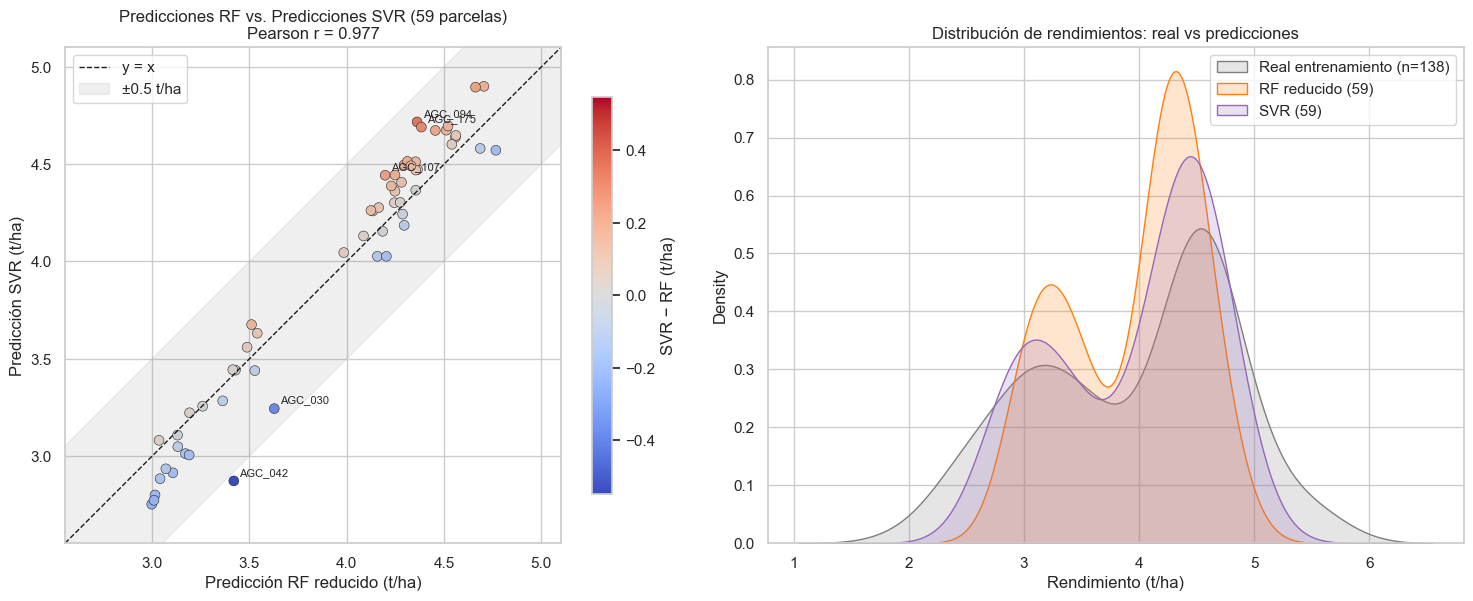

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.1]})

ax = axes[0]
lims = [min(comp_59.min()) - 0.2, max(comp_59.max()) + 0.2]
sc = ax.scatter(comp_59['RF reducido'], comp_59['SVR'], c=dif, cmap='coolwarm',
                vmin=-dif.abs().max(), vmax=dif.abs().max(), s=50, edgecolor='k', lw=0.4)
ax.plot(lims, lims, 'k--', lw=1, label='y = x')
ax.fill_between(lims, [l - 0.5 for l in lims], [l + 0.5 for l in lims], color='gray', alpha=0.12,
                label='±0.5 t/ha')
for idx in top_dif.index[:5]:
    ax.annotate(df_pred.loc[idx, 'id_poligono'], (comp_59.loc[idx, 'RF reducido'], comp_59.loc[idx, 'SVR']),
                fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect('equal')
ax.set_xlabel('Predicción RF reducido (t/ha)'); ax.set_ylabel('Predicción SVR (t/ha)')
ax.set_title(f'Predicciones RF vs. Predicciones SVR (59 parcelas)\nPearson r = {r_pearson:.3f}')
plt.colorbar(sc, ax=ax, label='SVR − RF (t/ha)', shrink=0.8)
ax.legend(loc='upper left')

ax = axes[1]
for serie, datos, color in [(f'Real entrenamiento (n={len(y_train)})', y_train, 'tab:gray'),
                            ('RF reducido (59)', comp_59['RF reducido'], 'tab:orange'),
                            ('SVR (59)', comp_59['SVR'], 'tab:purple')]:
    sns.kdeplot(datos, label=serie, color=color, fill=True, alpha=0.2, ax=ax)
ax.set_xlabel('Rendimiento (t/ha)')
ax.set_title('Distribución de rendimientos: real vs predicciones')
ax.legend()
plt.tight_layout(); plt.show()

### 7.2 Auditoría Agronómica de Discrepancias: Caso AGC_042 (Singuilucan)

En la parcela `AGC_042` (Singuilucan, Hidalgo, conjunto de predicción) el **RF reducido estima 3.42 t/ha** y el **SVR (rbf) 2.87 t/ha** (−0.55 t/ha). Es la mayor discrepancia de las 59 parcelas. Se audita en cuatro pasos:

1. **Perfil biofísico** de la parcela frente a las 138 de entrenamiento, en las 12 variables. Incluye el *Z-score*, que es exactamente lo que recibe el SVR tras el `StandardScaler`.
2. **Descomposición de cada predicción:**
   - **RF:** SHAP local (`TreeExplainer`) y voto de los 300 árboles.
   - **SVR:** vecinos más cercanos en el espacio estandarizado, contribución de cada vector de soporte y SHAP local exacto.

   Para que las contribuciones de ambos modelos sean comparables, los dos SHAP usan el mismo fondo: las 138 parcelas de entrenamiento (`interventional`). Así, en cada modelo la suma de contribuciones va de su predicción media en entrenamiento a la predicción de AGC_042.
3. **Top 5** parcelas con mayor discrepancia SVR − RF y sus variables más extremas.
4. **Visualización e interpretación agronómica.**

In [34]:
from sklearn.neighbors import NearestNeighbors

ID_CASO = 'AGC_042'
idx_caso = df_pred.index[df_pred['id_poligono'] == ID_CASO][0]
x_caso = X_pred.loc[[idx_caso], vars_reducido]

scaler_svr = svr_final.named_steps['standardscaler']
svr_model  = svr_final.named_steps['svr']
Z_train = pd.DataFrame(scaler_svr.transform(X_torneo), index=X_torneo.index, columns=vars_reducido)
Z_pred  = pd.DataFrame(scaler_svr.transform(X_pred[vars_reducido]), index=X_pred.index, columns=vars_reducido)
z_caso  = Z_pred.loc[idx_caso]

pred_rf_caso  = modelo_reducido.predict(x_caso)[0]
pred_svr_caso = svr_final.predict(x_caso)[0]
print(f"{ID_CASO} | {df_pred.loc[idx_caso, 'municipio']}, {df_pred.loc[idx_caso, 'estado']} | "
      f'RF reducido = {pred_rf_caso:.3f} t/ha | SVR = {pred_svr_caso:.3f} t/ha | '
      f'diferencia SVR - RF = {pred_svr_caso - pred_rf_caso:+.3f} t/ha')

# --- 1. Perfil biofísico vs distribución de entrenamiento
grupo = df_train['grupo_rend']
perfil = pd.DataFrame({
    'Valor_AGC_042': x_caso.iloc[0],
    'Media_Train': X_torneo.mean(),
    'Mediana_Train': X_torneo.median(),
    'Percentil_en_Train (%)': [(X_torneo[v] < x_caso.iloc[0][v]).mean() * 100
                               + (X_torneo[v] == x_caso.iloc[0][v]).mean() * 50 for v in vars_reducido],
    'Z_score': z_caso,
    'Media_Grupo_Bajo': X_torneo[grupo == 'Bajo'].mean(),
    'Media_Grupo_Alto': X_torneo[grupo == 'Alto'].mean(),
})
# ¿A qué grupo se parece más la parcela en cada variable?
perfil['Más cerca de'] = np.where((perfil['Valor_AGC_042'] - perfil['Media_Grupo_Bajo']).abs()
                                  < (perfil['Valor_AGC_042'] - perfil['Media_Grupo_Alto']).abs(), 'Bajo', 'Alto')
print(f'\nPerfil de {ID_CASO} en las {len(vars_reducido)} variables (orden de importancia SHAP):')
display(perfil.round(3))
print(f"Variables donde se parece más al grupo Bajo: {(perfil['Más cerca de'] == 'Bajo').sum()}/{len(perfil)} | "
      f"|Z| > 2 en: {perfil.index[perfil['Z_score'].abs() > 2].tolist()}")

AGC_042 | Singuilucan, Hidalgo | RF reducido = 3.420 t/ha | SVR = 2.873 t/ha | diferencia SVR - RF = -0.547 t/ha

Perfil de AGC_042 en las 12 variables (orden de importancia SHAP):


,Valor_AGC_042,Media_Train,Mediana_Train,Percentil_en_Train (%),Z_score,Media_Grupo_Bajo,Media_Grupo_Alto,Más cerca de
era5_vpd_medio_flor_kpa,0.274,0.255,0.245,65.217,0.334,0.299,0.223,Bajo
ac_lluvia_pre_mm,188.571,182.027,156.580,65.217,0.079,249.037,133.444,Alto
era5_sm2_flor,0.373,0.383,0.392,24.638,-0.476,0.370,0.392,Bajo
soil_agua_disp_mm,38.923,38.992,39.231,36.232,-0.064,38.245,39.534,Alto
pl_eos50_doy,284.000,297.558,301.500,16.304,-0.996,291.034,302.288,Bajo
ac_gdd_ciclo,1949.789,1886.687,1955.352,49.275,0.228,1781.219,1963.152,Alto
soil_soc_g_kg,19.192,19.409,19.445,47.101,-0.070,17.760,20.604,Alto
ac_lluvia_max_dia_ciclo_mm,76.923,43.858,40.043,96.377,2.314,48.156,40.743,Bajo
ac_balance_flor_mm,140.561,32.016,24.096,94.203,2.128,46.791,21.305,Bajo
ac_balance_ciclo_mm,525.838,130.412,107.950,99.275,2.930,161.303,108.016,Bajo


Variables donde se parece más al grupo Bajo: 6/12 | |Z| > 2 en: ['ac_lluvia_max_dia_ciclo_mm', 'ac_balance_flor_mm', 'ac_balance_ciclo_mm']


In [35]:
# --- 2a. Random Forest: SHAP local (fondo = 138 parcelas de entrenamiento) y voto de los 300 árboles
expl_rf = shap.TreeExplainer(modelo_reducido, data=shap.maskers.Independent(X_torneo, max_samples=len(X_torneo)),
                               feature_perturbation='interventional')
shap_rf_caso = pd.Series(expl_rf.shap_values(x_caso)[0], index=vars_reducido)
base_rf = float(np.ravel(expl_rf.expected_value)[0])

votos = np.array([arbol.predict(x_caso.values)[0] for arbol in modelo_reducido.estimators_])
print(f'RF: valor base (predicción media en train) = {base_rf:.3f} | suma SHAP = {shap_rf_caso.sum():+.3f} | '
      f'base + SHAP = {base_rf + shap_rf_caso.sum():.3f} (predicción = {pred_rf_caso:.3f})')
print(f'Voto de los {len(votos)} árboles: media = {votos.mean():.3f} | mediana = {np.median(votos):.3f} | '
      f'mín = {votos.min():.3f} | máx = {votos.max():.3f} | sd = {votos.std():.3f}')
print(f'  Árboles < 3.0 t/ha: {(votos < 3.0).sum()} ({(votos < 3.0).mean():.0%}) | '
      f'< 3.42: {(votos < 3.42).sum()} | ≥ 4.0: {(votos >= 4.0).sum()}')

# Mínimo alcanzable por un árbol: con min_samples_leaf=4 cada hoja promedia ≥ 4 rendimientos
hojas = modelo_reducido.apply(x_caso.values)[0]
tam_hoja = [arbol.tree_.n_node_samples[h] for arbol, h in zip(modelo_reducido.estimators_, hojas)]
print(f'Tamaño de la hoja que recibe a {ID_CASO}: mediana = {np.median(tam_hoja):.0f} muestras '
      f'(mín {min(tam_hoja)}, máx {max(tam_hoja)})')

RF: valor base (predicción media en train) = 3.948 | suma SHAP = -0.528 | base + SHAP = 3.420 (predicción = 3.420)
Voto de los 300 árboles: media = 3.420 | mediana = 3.269 | mín = 2.214 | máx = 5.200 | sd = 0.647
  Árboles < 3.0 t/ha: 87 (29%) | < 3.42: 184 | ≥ 4.0: 67
Tamaño de la hoja que recibe a AGC_042: mediana = 5 muestras (mín 4, máx 28)


In [36]:
# --- 2b. SVR: vecinos en el espacio estandarizado, contribución de vectores de soporte y SHAP local exacto
nn = NearestNeighbors(n_neighbors=5).fit(Z_train)
dist, pos = nn.kneighbors(z_caso.values.reshape(1, -1))
vecinos = df_train.iloc[pos[0]][['id_poligono', 'municipio', 'estado', 'grupo_rend', col_target, col_pesos]].copy()
vecinos.insert(3, 'distancia', dist[0])
vecinos['kernel_rbf'] = np.exp(-svr_model._gamma * vecinos['distancia'] ** 2)
vecinos['pred_OOF_RF'] = pd.Series(y_oof_reducido, index=df_train.index).loc[vecinos.index]
vecinos['pred_OOF_SVR'] = pd.Series(oof_torneo['StandardScaler + SVR (rbf)'], index=df_train.index).loc[vecinos.index]
d_todas = np.sqrt(((Z_train - z_caso) ** 2).sum(axis=1))
print(f'5 parcelas de entrenamiento más cercanas a {ID_CASO} (12 variables estandarizadas; '
      f'gamma = {svr_model._gamma:.4f}; distancia mediana a todo train = {d_todas.median():.2f}):')
display(vecinos.round(3))
print(f'Rendimiento medio de los 5 vecinos = {vecinos[col_target].mean():.3f} t/ha')

# Descomposición exacta del SVR: f(x) = b + Σ alpha_i · K(sv_i, x)
K_sv = np.exp(-svr_model._gamma * ((svr_model.support_vectors_ - z_caso.values) ** 2).sum(axis=1))
contrib_sv = pd.DataFrame({'id_poligono': df_train['id_poligono'].iloc[svr_model.support_].values,
                           'rendimiento_t_ha': y_train.iloc[svr_model.support_].values,
                           'alpha': svr_model.dual_coef_[0], 'K(sv, x)': K_sv,
                           'contribución': svr_model.dual_coef_[0] * K_sv})
print(f'\nSVR: intercepto b = {svr_model.intercept_[0]:.3f} | Σ contribuciones = {contrib_sv["contribución"].sum():+.3f} | '
      f'b + Σ = {svr_model.intercept_[0] + contrib_sv["contribución"].sum():.3f} | '
      f'{len(contrib_sv)} vectores de soporte de {len(y_train)}')
print('Vectores de soporte que más empujan la predicción (|contribución|):')
display(contrib_sv.reindex(contrib_sv['contribución'].abs().sort_values(ascending=False).index).head(8).round(4))

# SHAP local exacto del SVR (2^12 coaliciones x 138 parcelas de fondo)
expl_svr = shap.explainers.Exact(svr_final.predict, shap.maskers.Independent(X_torneo, max_samples=len(X_torneo)))
sv_svr = expl_svr(x_caso)
shap_svr_caso = pd.Series(sv_svr.values[0], index=vars_reducido)
base_svr = float(sv_svr.base_values[0])
print(f'\nSVR: valor base = {base_svr:.3f} | suma SHAP = {shap_svr_caso.sum():+.3f} | '
      f'base + SHAP = {base_svr + shap_svr_caso.sum():.3f} (predicción = {pred_svr_caso:.3f})')

5 parcelas de entrenamiento más cercanas a AGC_042 (12 variables estandarizadas; gamma = 0.0833; distancia mediana a todo train = 5.85):


,id_poligono,municipio,estado,distancia,grupo_rend,rendimiento_t_ha,diag_y_resolucion,kernel_rbf,pred_OOF_RF,pred_OOF_SVR
33,AGC_034,Singuilucan,Hidalgo,1.953,Bajo,2.0,0.5,0.728,3.774,3.279
37,AGC_038,Singuilucan,Hidalgo,2.541,Bajo,3.3,0.1,0.584,3.298,3.085
139,AGC_140,Singuilucan,Hidalgo,2.574,Bajo,3.2,0.1,0.576,3.272,2.939
6,AGC_007,Singuilucan,Hidalgo,2.709,Bajo,3.5,0.5,0.543,3.428,3.102
40,AGC_041,Singuilucan,Hidalgo,2.722,Bajo,2.5,0.5,0.539,3.342,3.374


Rendimiento medio de los 5 vecinos = 2.900 t/ha

SVR: intercepto b = 3.821 | Σ contribuciones = -0.948 | b + Σ = 2.873 | 114 vectores de soporte de 138
Vectores de soporte que más empujan la predicción (|contribución|):


,id_poligono,rendimiento_t_ha,alpha,"K(sv, x)",contribución
20,AGC_034,2.0,-1.0000,0.7276,-0.7276
25,AGC_041,2.5,-1.0000,0.5392,-0.5392
4,AGC_007,3.5,0.9325,0.5425,0.5059
98,AGC_166,2.5,-1.0000,0.4767,-0.4767
48,AGC_079,3.3,-0.8964,0.4412,-0.3955
47,AGC_078,3.0,-1.0000,0.3755,-0.3755
68,AGC_121,3.3,1.0000,0.3509,0.3509
49,AGC_081,3.7,1.0000,0.3412,0.3412



SVR: valor base = 3.986 | suma SHAP = -1.113 | base + SHAP = 2.873 (predicción = 2.873)


In [37]:
# --- Comparación frente a frente de contribuciones
comp_shap = pd.DataFrame({'Z_score': z_caso, 'SHAP_RF': shap_rf_caso, 'SHAP_SVR': shap_svr_caso})
comp_shap['SVR - RF'] = comp_shap['SHAP_SVR'] - comp_shap['SHAP_RF']
comp_shap = comp_shap.reindex(comp_shap['SVR - RF'].abs().sort_values(ascending=False).index)
fila_tot = pd.DataFrame({'Z_score': [np.nan], 'SHAP_RF': [shap_rf_caso.sum()], 'SHAP_SVR': [shap_svr_caso.sum()],
                         'SVR - RF': [shap_svr_caso.sum() - shap_rf_caso.sum()]}, index=['TOTAL (Σ SHAP)'])
fila_base = pd.DataFrame({'Z_score': [np.nan], 'SHAP_RF': [base_rf], 'SHAP_SVR': [base_svr],
                          'SVR - RF': [base_svr - base_rf]}, index=['Valor base'])
print(f'Contribuciones SHAP locales de {ID_CASO} (t/ha), ordenadas por discrepancia entre modelos:')
display(pd.concat([comp_shap, fila_tot, fila_base]).round(4))

# Ratio de amortiguamiento: cuánto de la señal del SVR traslada el RF en cada variable
mismo_signo = np.sign(comp_shap['SHAP_RF']) == np.sign(comp_shap['SHAP_SVR'])
print(f'Variables con el mismo signo en ambos modelos: {mismo_signo.sum()}/{len(comp_shap)}')
print(f'Σ|SHAP| RF = {shap_rf_caso.abs().sum():.3f} vs Σ|SHAP| SVR = {shap_svr_caso.abs().sum():.3f} '
      f'(el RF mueve {shap_rf_caso.abs().sum() / shap_svr_caso.abs().sum():.0%} de lo que mueve el SVR)')

Contribuciones SHAP locales de AGC_042 (t/ha), ordenadas por discrepancia entre modelos:


,Z_score,SHAP_RF,SHAP_SVR,SVR - RF
ac_balance_ciclo_mm,2.9303,-0.1546,-0.3252,-0.1706
ac_balance_flor_mm,2.1281,-0.2099,-0.3059,-0.0960
ac_lluvia_max_dia_ciclo_mm,2.3142,-0.1458,-0.2318,-0.0859
era5_vpd_medio_flor_kpa,0.3336,0.0049,-0.0551,-0.0600
pl_eos50_doy,-0.9958,-0.0307,-0.0877,-0.0570
soil_agua_disp_mm,-0.0636,-0.0032,-0.0434,-0.0402
pend_media_grados,0.5305,0.0569,0.0201,-0.0368
soil_soc_g_kg,-0.0695,-0.0060,-0.0322,-0.0261
era5_sm2_flor,-0.4762,-0.0566,-0.0754,-0.0188
ac_lluvia_pre_mm,0.0792,-0.0187,-0.0309,-0.0122


Variables con el mismo signo en ambos modelos: 11/12
Σ|SHAP| RF = 0.755 vs Σ|SHAP| SVR = 1.274 (el RF mueve 59% de lo que mueve el SVR)


In [38]:
# --- 3. Top 5 parcelas con mayor discrepancia SVR - RF
def z_extremos(i, n=2):
    z = Z_pred.loc[i]
    return ', '.join(f'{v} (z={z[v]:+.2f})' for v in z.abs().sort_values(ascending=False).index[:n])

idx_top5 = dif.abs().sort_values(ascending=False).index[:5]
top5_disc = df_pred.loc[idx_top5, ['id_poligono', 'municipio', 'estado']].assign(
    Pred_RF=comp_59.loc[idx_top5, 'RF reducido'], Pred_SVR=comp_59.loc[idx_top5, 'SVR'],
    Diferencia=dif.loc[idx_top5],
    Z_max_global=[Z_pred.loc[i].abs().max() for i in idx_top5],
    Variables_mas_extremas=[z_extremos(i) for i in idx_top5])
pd.set_option('display.max_colwidth', 90)
display(top5_disc.round(3))

# ¿Las discrepancias crecen con lo atípica que es la parcela?
atipicidad = np.sqrt((Z_pred ** 2).sum(axis=1))
print(f'Correlación |SVR - RF| vs distancia al centro del train (59 parcelas): '
      f'{np.corrcoef(dif.abs(), atipicidad)[0, 1]:.3f}')
print(f'Correlación (SVR - RF) vs predicción RF: {np.corrcoef(dif, comp_59["RF reducido"])[0, 1]:.3f} '
      '(positiva = el SVR estira las colas que el RF comprime: más bajo donde el RF predice bajo, más alto donde predice alto)')

,id_poligono,municipio,estado,Pred_RF,Pred_SVR,Diferencia,Z_max_global,Variables_mas_extremas
41,AGC_042,Singuilucan,Hidalgo,3.420,2.873,-0.547,2.930,"ac_balance_ciclo_mm (z=+2.93), ac_lluvia_max_dia_ciclo_mm (z=+2.31)"
29,AGC_030,Singuilucan,Hidalgo,3.628,3.244,-0.383,2.359,"ac_balance_ciclo_mm (z=+2.36), ac_lluvia_max_dia_ciclo_mm (z=+2.15)"
93,AGC_094,Chignahuapan,Puebla,4.361,4.717,0.356,2.885,"ac_gdd_ciclo (z=-2.88), era5_vpd_medio_flor_kpa (z=-1.41)"
174,AGC_175,Chignahuapan,Puebla,4.383,4.690,0.307,2.810,"ac_gdd_ciclo (z=-2.81), soil_soc_g_kg (z=+1.73)"
106,AGC_107,Almoloya,Hidalgo,4.197,4.443,0.246,1.310,"soil_agua_disp_mm (z=-1.31), ac_balance_flor_mm (z=-1.30)"


Correlación |SVR - RF| vs distancia al centro del train (59 parcelas): 0.036
Correlación (SVR - RF) vs predicción RF: 0.559 (positiva = el SVR estira las colas que el RF comprime: más bajo donde el RF predice bajo, más alto donde predice alto)


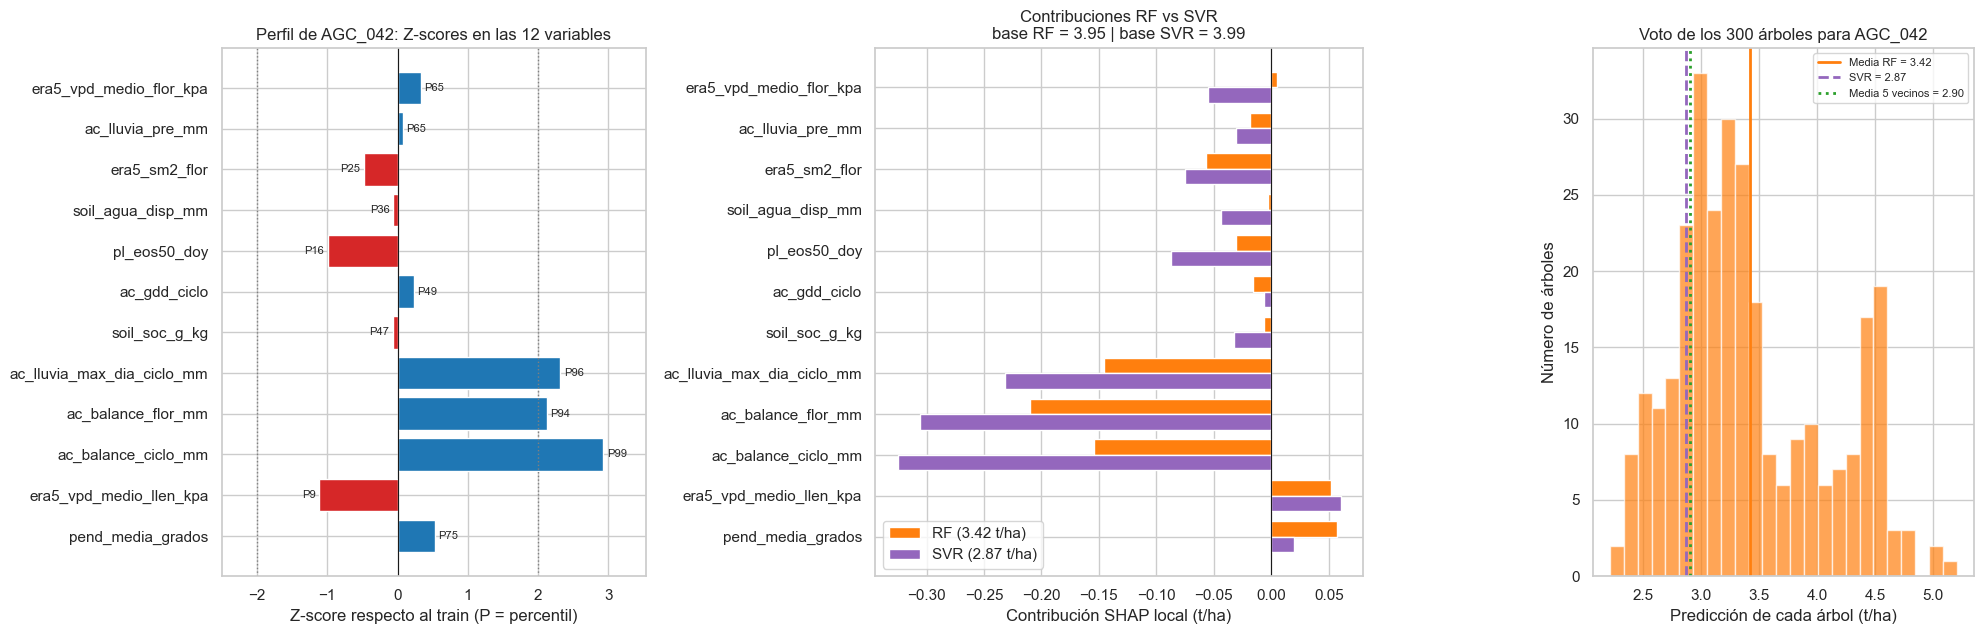

In [39]:
# --- 4. Visualización
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), gridspec_kw={'width_ratios': [1, 1.15, 0.9]})
orden_v = perfil.index[::-1]

ax = axes[0]
zc = perfil.loc[orden_v, 'Z_score']
ax.barh(orden_v, zc, color=['tab:red' if z < 0 else 'tab:blue' for z in zc])
for y_pos, v in enumerate(orden_v):
    ax.text(zc[v] + (0.05 if zc[v] >= 0 else -0.05), y_pos, f"P{perfil.loc[v, 'Percentil_en_Train (%)']:.0f}",
            va='center', ha='left' if zc[v] >= 0 else 'right', fontsize=8)
for lim in (-2, 2):
    ax.axvline(lim, color='gray', ls=':', lw=1)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlim(min(-2.5, zc.min() - 0.6), max(2.5, zc.max() + 0.6))
ax.set_xlabel('Z-score respecto al train (P = percentil)')
ax.set_title(f'Perfil de {ID_CASO}: Z-scores en las 12 variables')

ax = axes[1]
ypos = np.arange(len(orden_v)); h = 0.38
ax.barh(ypos + h / 2, shap_rf_caso[orden_v], h, color='tab:orange', label=f'RF ({pred_rf_caso:.2f} t/ha)')
ax.barh(ypos - h / 2, shap_svr_caso[orden_v], h, color='tab:purple', label=f'SVR ({pred_svr_caso:.2f} t/ha)')
ax.set_yticks(ypos); ax.set_yticklabels(orden_v)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('Contribución SHAP local (t/ha)')
ax.set_title(f'Contribuciones RF vs SVR\nbase RF = {base_rf:.2f} | base SVR = {base_svr:.2f}')
ax.legend(loc='lower left')

ax = axes[2]
ax.hist(votos, bins=25, color='tab:orange', alpha=0.7, edgecolor='white')
ax.axvline(pred_rf_caso, color='tab:orange', lw=2, label=f'Media RF = {pred_rf_caso:.2f}')
ax.axvline(pred_svr_caso, color='tab:purple', lw=2, ls='--', label=f'SVR = {pred_svr_caso:.2f}')
ax.axvline(vecinos[col_target].mean(), color='tab:green', lw=2, ls=':',
           label=f'Media 5 vecinos = {vecinos[col_target].mean():.2f}')
ax.set_xlabel('Predicción de cada árbol (t/ha)'); ax.set_ylabel('Número de árboles')
ax.set_title(f'Voto de los 300 árboles para {ID_CASO}')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Interpretación agronómica y matemática del caso AGC_042

**1. Qué tiene AGC_042: exceso de agua, no sequía.**
La parcela **no muestra estrés hídrico ni térmico**:
- **VPD en floración moderado:** 0.27 kPa (P65, z = +0.33).
- **VPD en llenado bajo:** 0.21 kPa (P9).
- **Lluvia previa a la siembra normal:** P65.
- **Suelo promedio:** agua disponible P36 y carbono orgánico P47.

Lo que la distingue es un **régimen de lluvia extremo**, el más alto de todo el conjunto de entrenamiento:

| Variable | AGC_042 | Media train | Percentil | z |
|---|---|---|---|---|
| `ac_balance_ciclo_mm` (lluvia − demanda en el ciclo) | **+526 mm** | +130 mm | **P99** | **+2.93** |
| `ac_lluvia_max_dia_ciclo_mm` (tormenta máxima de un día) | **77 mm** | 44 mm | **P96** | **+2.31** |
| `ac_balance_flor_mm` (balance en floración) | **+141 mm** | +32 mm | **P94** | **+2.13** |
| `pl_eos50_doy` (fin de temporada, día del año) | **284** | 298 | P16 | −1.00 |

Agronómicamente, este patrón apunta a **excedente hídrico durante el ciclo y en plena floración**, con tormentas intensas (77 mm en un día). En cebada eso se asocia a:
- encharcamiento e hipoxia radicular en suelos de baja infiltración;
- lixiviación de nitrógeno;
- acame por tormentas;
- mayor presión de enfermedades foliares y de espiga (roya, mancha reticular, fusariosis) con alta humedad en floración.

El **fin de temporada temprano** (unos 14 días antes que la media, P16) es coherente con una senescencia acelerada o un llenado acortado. La pendiente algo mayor (3.9°, P75) es lo único que el modelo interpreta a favor, quizá porque favorece el drenaje. En el entrenamiento, **el grupo Bajo tiene en promedio más balance hídrico que el Alto** (161 frente a 108 mm en el ciclo y 47 frente a 21 mm en floración): en esta zona el exceso de agua penaliza más que la falta de ella.

**2. Por qué el SVR proyecta 2.87 t/ha.**
- **Vecinos:** el kernel RBF (γ = 1/12) es una media ponderada por similitud en el espacio estandarizado. Las 5 parcelas de entrenamiento más cercanas a AGC_042 son **todas de Singuilucan y del grupo Bajo**: AGC_034 (2.0 t/ha), AGC_038 (3.3), AGC_140 (3.2), AGC_007 (3.5) y AGC_041 (2.5). Su media es **2.90 t/ha**, prácticamente la predicción del SVR.
- **Vectores de soporte:** la descomposición exacta muestra que **AGC_034 (2.0 t/ha) es el que más pesa** (kernel 0.73, contribución −0.73 t/ha), seguido de AGC_041 (−0.54) y AGC_166 (−0.48). La predicción queda en b + Σ = 3.82 − 0.95 = 2.87.
- **SHAP:** el SVR atribuye **−0.86 t/ha solo a las tres variables de lluvia y balance**. En total resta −1.11 t/ha a su valor base de 3.99.

**3. Por qué el RF amortigua la caída a 3.42 t/ha.** Las 12 variables restan en el mismo sentido en ambos modelos (salvo el VPD de floración, que es casi nulo en el RF), pero el RF **solo traslada el 59 % de la magnitud** (Σ|SHAP| 0.76 frente a 1.27). Hay tres mecanismos:
- **Saturación de los árboles:** un árbol divide por umbrales, así que un balance de +526 mm cae en la misma hoja que uno de +250 mm. El z = +2.9 no se aprovecha más allá del último corte. En el SVR, la distancia sí crece con lo extremo del valor.
- **`max_features='sqrt'`:** cada división ve unas 3 de las 12 variables. Muchos árboles no llegan a usar las variables de balance y clasifican la parcela por las demás, que son normales. Por eso **el voto de los 300 árboles es bimodal**: la mayoría la sitúa entre 2.2 y 3.5 t/ha (mediana 3.27; 87 árboles por debajo de 3.0), pero **67 árboles la ponen en 4.0 t/ha o más**, y ese grupo arrastra la media a 3.42.
- **Hojas con al menos 4 muestras:** cada hoja promedia como mínimo 4 rendimientos (mediana de 5), lo que diluye los valores extremos como el 2.0 t/ha de AGC_034.

**4. ¿A quién creerle?** En los 5 vecinos de entrenamiento (rendimiento real medio 2.90), las predicciones fuera de pliegue del **RF promedian 3.42 y las del SVR 3.16**. El RF **sobrestima sistemáticamente este grupo de Singuilucan**; en AGC_034 predice 3.77 cuando el real es 2.0. El SVR se acerca más a lo observado en esta zona. Esto, junto con la estabilidad en 10 semillas (sección 7.1), da más credibilidad al **SVR (≈2.9 t/ha)** para AGC_042.

Hay dos advertencias:
- **Precisión de los vecinos:** 3 de los 5 tienen `diag_y_resolucion = 0.5` (rendimiento redondeado a media tonelada), incluido AGC_034, el que más pesa.
- **Dependencia de una parcela:** la predicción del SVR depende bastante de AGC_034. Si su 2.0 t/ha fuera un registro anómalo, la predicción subiría.

**5. Patrón general (Top 5 de discrepancias).** Las discrepancias **no se deben a parcelas atípicas en general**: la correlación entre |SVR − RF| y la distancia al centro del entrenamiento es 0.04. Se deben a **extremos en variables concretas**:
- **Singuilucan con exceso de lluvia** (AGC_042 y AGC_030, con z de +2.4 a +2.9 en balance y tormenta máxima): el SVR predice más bajo.
- **Chignahuapan con muy pocos grados-día** (AGC_094 y AGC_175, z ≈ −2.8 en `ac_gdd_ciclo`, es decir, clima fresco, que en este conjunto se asocia al grupo Alto): el SVR predice más alto.

En conjunto, (SVR − RF) correlaciona +0.56 con la predicción del RF: **el SVR estira las dos colas que el RF comprime hacia la media**. Es el comportamiento esperado de un bosque con árboles poco profundos (`max_depth=5`, `min_samples_leaf=4`) frente a un kernel local.

## 8. Modelo final: SVR (12 variables) y exportación definitiva de los CSV

Tras validar la estabilidad multi-semilla (7.1) y el comportamiento agronómico (7.2), se adopta como **modelo final de estimación** el pipeline:

```python
make_pipeline(StandardScaler(), SVR(kernel='rbf', C=1.0, epsilon=0.1, gamma='scale'))
```

entrenado con las 12 variables óptimas (`vars_reducido`). Esta es la **única celda del notebook que escribe los CSV**:

| Archivo | Contenido |
|---|---|
| `dataset_comparacion_rendimientos.csv` | Valor real en entrenamiento; para cada modelo (RF 51 vars, RF 12 vars, SVR 12 vars) la predicción OOF en entrenamiento y la estimación en predicción |
| `dataset_rendimientos_estimados_svr12.csv` | Valor real en las 138 parcelas de entrenamiento + estimación del **SVR de 12 variables** en las 59 de predicción |

In [40]:
# --- 1. Modelo final: OOF (splits, semilla 42) y ajuste con el 100 % del entrenamiento
modelo_final_svr = make_pipeline(StandardScaler(), SVR(kernel='rbf', C=1.0, epsilon=0.1, gamma='scale'))
X_train_svr = X_train[vars_reducido]
X_pred_svr  = X_pred[vars_reducido]

y_oof_svr = cross_val_predict(clone(modelo_final_svr), X_train_svr, y_train, cv=splits, n_jobs=1)
modelo_final_svr.fit(X_train_svr, y_train)
y_pred_svr = modelo_final_svr.predict(X_pred_svr)

# Coherencia con las secciones 7 y 7.1
assert np.allclose(y_oof_svr, oof_torneo['StandardScaler + SVR (rbf)']), 'OOF del SVR distinto al del torneo'
assert np.allclose(y_pred_svr, svr_final.predict(X_pred_svr)), 'Predicción del SVR distinta a la de 7.1'

print(f'Modelo final: {modelo_final_svr}')
print(f'Variables ({len(vars_reducido)}): {vars_reducido}')
print(f'y_oof_svr : {y_oof_svr.shape} | y_pred_svr: {y_pred_svr.shape}')
display(pd.DataFrame({'SVR 12 vars (final)': calcular_metricas(y_train, y_oof_svr),
                      'RF 12 vars': calcular_metricas(y_train, y_oof_reducido),
                      f'RF {N_VARS} vars': calcular_metricas(y_train, y_oof_50vars)}).T
          .rename(columns={'MAPE': 'MAPE (%)', 'R2': 'R²'}).round(4))

Modelo final: Pipeline(steps=[('standardscaler', StandardScaler()), ('svr', SVR())])
Variables (12): ['era5_vpd_medio_flor_kpa', 'ac_lluvia_pre_mm', 'era5_sm2_flor', 'soil_agua_disp_mm', 'pl_eos50_doy', 'ac_gdd_ciclo', 'soil_soc_g_kg', 'ac_lluvia_max_dia_ciclo_mm', 'ac_balance_flor_mm', 'ac_balance_ciclo_mm', 'era5_vpd_medio_llen_kpa', 'pend_media_grados']
y_oof_svr : (138,) | y_pred_svr: (59,)


,RMSE,MAE,MAPE (%),R²
SVR 12 vars (final),0.5314,0.3861,11.1078,0.6073
RF 12 vars,0.5579,0.4314,12.2591,0.5672
RF 51 vars,0.5797,0.4522,12.9327,0.5327


In [41]:
# --- 2 y 3. Reconstrucción de las 197 filas (orden original de dataset_greedy.csv) y exportación
def unir(oof, pred):
    # OOF en las filas de entrenamiento y estimación en las de predicción, alineado al índice de df
    return pd.concat([pd.Series(oof, index=df_train.index),
                      pd.Series(pred, index=df_pred.index)]).reindex(df.index)

es_train = df['conjunto'] == 'ENTRENAMIENTO'
cols_id = ['id_poligono', 'estado', 'municipio', 'conjunto']

df_comparacion_final = df[cols_id].copy()
df_comparacion_final['rendimiento_t_ha']            = df[col_target].where(es_train)
df_comparacion_final['rendimiento_pred_50vars']     = unir(y_oof_50vars, y_pred_50vars)
df_comparacion_final['rendimiento_pred_rf_12vars']  = unir(y_oof_reducido, y_pred_reducido)
df_comparacion_final['rendimiento_pred_svr_12vars'] = unir(y_oof_svr, y_pred_svr)
df_comparacion_final = df_comparacion_final[cols_id + ['rendimiento_t_ha', 'rendimiento_pred_50vars',
                                                       'rendimiento_pred_rf_12vars', 'rendimiento_pred_svr_12vars']]

df_estimados_final = df[cols_id].copy()
df_estimados_final['rendimiento_t_ha'] = df[col_target].where(es_train, unir(y_oof_svr, y_pred_svr))
df_estimados_final = df_estimados_final[cols_id + ['rendimiento_t_ha']]

ruta_comp = DATA_DIR / 'dataset_comparacion_rendimientos.csv'
ruta_est  = DATA_DIR / 'dataset_rendimientos_estimados_svr12.csv'
df_comparacion_final.to_csv(ruta_comp, index=False)
df_estimados_final.to_csv(ruta_est, index=False)
print(f'Exportado: {ruta_comp.resolve()}  {df_comparacion_final.shape}')
print(f'Exportado: {ruta_est.resolve()}  {df_estimados_final.shape}')

Exportado: data\modelado\dataset_comparacion_rendimientos.csv  (197, 8)
Exportado: data\modelado\dataset_rendimientos_estimados_svr12.csv  (197, 5)


In [42]:
# --- 4. Auditoría final: lectura desde disco de ambos CSV
comp_final = pd.read_csv(ruta_comp)
est_final  = pd.read_csv(ruta_est)

cols_comp_esp = ['id_poligono', 'estado', 'municipio', 'conjunto', 'rendimiento_t_ha',
                 'rendimiento_pred_50vars', 'rendimiento_pred_rf_12vars', 'rendimiento_pred_svr_12vars']
cols_est_esp  = ['id_poligono', 'estado', 'municipio', 'conjunto', 'rendimiento_t_ha']

for nombre, d in [(ruta_comp.name, comp_final), (ruta_est.name, est_final)]:
    print('=' * 100)
    print(f'{nombre} | shape = {d.shape}')
    display(d.head())
    print('Nulos por columna:')
    print(d.isna().sum().to_string())

# Estructura y nulos
assert comp_final.shape == (197, 8) and list(comp_final.columns) == cols_comp_esp
assert est_final.shape == (197, 5) and list(est_final.columns) == cols_est_esp
nulos_comp = comp_final.isna().sum()
assert nulos_comp['rendimiento_t_ha'] == 59 and nulos_comp.drop('rendimiento_t_ha').sum() == 0
assert comp_final.loc[comp_final['conjunto'] == 'PREDICCION', 'rendimiento_t_ha'].isna().all()
assert est_final.isna().sum().sum() == 0

# Orden original y reglas de llenado
assert (comp_final['id_poligono'].values == df['id_poligono'].values).all()
assert (est_final['id_poligono'].values == df['id_poligono'].values).all()
tr_mask = (est_final['conjunto'] == 'ENTRENAMIENTO').values
assert np.allclose(est_final.loc[tr_mask, 'rendimiento_t_ha'], df_train[col_target].values)
assert np.allclose(est_final.loc[~tr_mask, 'rendimiento_t_ha'], y_pred_svr)
assert np.allclose(comp_final.loc[tr_mask, 'rendimiento_pred_svr_12vars'], y_oof_svr)
assert np.allclose(comp_final.loc[~tr_mask, 'rendimiento_pred_svr_12vars'], y_pred_svr)
assert np.allclose(comp_final.loc[~tr_mask, 'rendimiento_pred_rf_12vars'], y_pred_reducido)
assert np.allclose(comp_final.loc[~tr_mask, 'rendimiento_pred_50vars'], y_pred_50vars)

# Estadísticas de rendimiento_t_ha en el dataset maestro final
desc = est_final.groupby('conjunto')['rendimiento_t_ha'].agg(['count', 'mean', 'std', 'min', 'max'])
desc.loc['TOTAL (197)'] = est_final['rendimiento_t_ha'].agg(['count', 'mean', 'std', 'min', 'max'])
desc = desc.rename(index={'ENTRENAMIENTO': 'ENTRENAMIENTO (real)', 'PREDICCION': 'PREDICCION (SVR 12 vars)'},
                   columns={'count': 'n', 'mean': 'Media', 'std': 'Desv. est.', 'min': 'Mín', 'max': 'Máx'})
desc['n'] = desc['n'].astype(int)
print('=' * 100)
print(f'{ruta_est.name} — rendimiento_t_ha (t/ha) por conjunto:')
display(desc.round(3))
print('Auditoría final superada: 197 filas en ambos archivos, columnas y orden correctos, '
      '59 nulos solo en rendimiento_t_ha (comparación) y 0 nulos en el dataset maestro final.')

dataset_comparacion_rendimientos.csv | shape = (197, 8)


,id_poligono,estado,municipio,conjunto,rendimiento_t_ha,rendimiento_pred_50vars,rendimiento_pred_rf_12vars,rendimiento_pred_svr_12vars
0,AGC_001,Tlaxcala,Calpulalpan,ENTRENAMIENTO,3.50,3.202254,3.090676,2.944969
1,AGC_002,Puebla,Chignahuapan,ENTRENAMIENTO,4.63,4.157066,4.241730,4.204273
2,AGC_003,Hidalgo,Singuilucan,PREDICCION,NaN,3.701611,3.510935,3.675798
3,AGC_004,Tlaxcala,Calpulalpan,ENTRENAMIENTO,3.00,3.149588,3.118083,3.191450
4,AGC_005,Puebla,Chignahuapan,ENTRENAMIENTO,5.16,4.228840,4.369097,4.482775


Nulos por columna:
id_poligono                     0
estado                          0
municipio                       0
conjunto                        0
rendimiento_t_ha               59
rendimiento_pred_50vars         0
rendimiento_pred_rf_12vars      0
rendimiento_pred_svr_12vars     0
dataset_rendimientos_estimados_svr12.csv | shape = (197, 5)


,id_poligono,estado,municipio,conjunto,rendimiento_t_ha
0,AGC_001,Tlaxcala,Calpulalpan,ENTRENAMIENTO,3.500000
1,AGC_002,Puebla,Chignahuapan,ENTRENAMIENTO,4.630000
2,AGC_003,Hidalgo,Singuilucan,PREDICCION,3.675798
3,AGC_004,Tlaxcala,Calpulalpan,ENTRENAMIENTO,3.000000
4,AGC_005,Puebla,Chignahuapan,ENTRENAMIENTO,5.160000


Nulos por columna:
id_poligono         0
estado              0
municipio           0
conjunto            0
rendimiento_t_ha    0
dataset_rendimientos_estimados_svr12.csv — rendimiento_t_ha (t/ha) por conjunto:


,n,Media,Desv. est.,Mín,Máx
conjunto,,,,,
ENTRENAMIENTO (real),138,3.955,0.851,2.000,5.59
PREDICCION (SVR 12 vars),59,3.962,0.675,2.753,4.90
TOTAL (197),197,3.957,0.801,2.000,5.59


Auditoría final superada: 197 filas en ambos archivos, columnas y orden correctos, 59 nulos solo en rendimiento_t_ha (comparación) y 0 nulos en el dataset maestro final.


## 9. Síntesis Ejecutiva de Variables Clave para la Predicción del Rendimiento

Esta sección responde tres preguntas con dos lentes complementarias:

| Lente | Modelo | Métrica | Qué mide |
|---|---|---|---|
| **Exploratoria** | RF de 51 variables (`modelo_50vars`) | `mean(|SHAP|)` en t/ha | Relevancia de **todas** las variables candidatas |
| **Confirmatoria** | **SVR final de 12 variables** | `permutation_importance` en los 5 pliegues OOF (ΔRMSE, t/ha) y KernelSHAP | Cuánto empeora el modelo final si se rompe cada variable |

La sección termina con una **ablación por grupos biofísicos** en el SVR (5 pliegues de la semilla 42 y promedio de 10 semillas), que muestra por qué la combinación de las 12 variables funciona mejor que cualquier grupo aislado.

> Esta sección **no modifica variables previas ni escribe archivos**.

In [43]:
from sklearn.inspection import permutation_importance

# --- Clasificación de variables
def fuente(v):
    if v.startswith('pl_'):   return 'Planet (fenología)'
    if v.startswith('s2_'):   return 'Sentinel-2 (fenología)'
    if v.startswith('era5_'): return 'ERA5 (clima)'
    if v.startswith('ac_'):   return 'Agroclima (agua/térmico)'
    if v.startswith(('soil_', 'pend_', 'elev_', 'dz_', 'area_')): return 'Suelo/Topografía'
    return 'Otra'

def etapa(v):
    if '_pre_' in v or v.endswith('_pre'): return 'Pre-siembra'
    if 'siembra' in v:      return 'Siembra'
    if 'hasta_flor' in v:   return 'Siembra → floración'
    if '_veg' in v:         return 'Vegetativa'
    if '_flor' in v:        return 'Floración'
    if '_llen' in v or 'post_pico' in v: return 'Llenado de grano'
    return 'Ciclo completo'

def grupo_biofisico(v):
    if v.startswith('era5_'): return 'Clima y estrés atmosférico'
    if v.startswith('ac_'):   return 'Balance hídrico y precipitación'
    if v.startswith(('pl_', 's2_')): return 'Fenología satelital'
    if v.startswith(('soil_', 'pend_', 'elev_', 'dz_')): return 'Suelo y topografía'
    return 'Otro'

GRUPOS = ['Clima y estrés atmosférico', 'Balance hídrico y precipitación',
          'Fenología satelital', 'Suelo y topografía']
COLOR_GRUPO = dict(zip(GRUPOS, ['tab:red', 'tab:blue', 'tab:green', 'tab:brown']))

# --- Lente exploratoria: SHAP del RF de 51 variables (calculado en la sección 3)
shap51 = shap_importance.copy()
shap51_pct = shap51 / shap51.sum() * 100
corr_y = X_train.corrwith(y_train)                          # Pearson con rendimiento_t_ha
corr_s = X_train.corrwith(y_train, method='spearman')

# --- Lente confirmatoria: permutation_importance del SVR final en cada pliegue OOF
filas_perm = []
for k, (tr, va) in enumerate(splits, 1):
    m = clone(modelo_final_svr).fit(X_train_svr.iloc[tr], y_train.iloc[tr])
    pi = permutation_importance(m, X_train_svr.iloc[va], y_train.iloc[va], n_repeats=30,
                                scoring='neg_root_mean_squared_error', random_state=42, n_jobs=1)
    filas_perm.append(pd.Series(pi.importances_mean, index=vars_reducido, name=k))
perm_svr = pd.concat(filas_perm, axis=1)
perm_svr_media = perm_svr.mean(axis=1).sort_values(ascending=False)   # ΔRMSE medio (t/ha)
perm_svr_sd    = perm_svr.std(axis=1)

# --- KernelSHAP del SVR final (fondo = 20 centroides k-means del train; 138 parcelas explicadas)
fondo_svr = shap.kmeans(X_train_svr, 20)
predict_svr = lambda A: modelo_final_svr.predict(pd.DataFrame(A, columns=vars_reducido))
expl_svr_k = shap.KernelExplainer(predict_svr, fondo_svr)
shap_svr_train = expl_svr_k.shap_values(X_train_svr, nsamples=1000, silent=True)
shap_svr12 = pd.Series(np.abs(shap_svr_train).mean(axis=0), index=vars_reducido).sort_values(ascending=False)
shap_svr12_pct = shap_svr12 / shap_svr12.sum() * 100

print(f'Permutation importance del SVR (ΔRMSE OOF medio en 5 pliegues, 30 repeticiones):')
display(pd.DataFrame({'ΔRMSE (t/ha)': perm_svr_media, 'sd entre pliegues': perm_svr_sd.reindex(perm_svr_media.index),
                      'mean|SHAP| SVR (t/ha)': shap_svr12.reindex(perm_svr_media.index),
                      '% SHAP SVR': shap_svr12_pct.reindex(perm_svr_media.index)}).round(4))

Permutation importance del SVR (ΔRMSE OOF medio en 5 pliegues, 30 repeticiones):


,ΔRMSE (t/ha),sd entre pliegues,mean|SHAP| SVR (t/ha),% SHAP SVR
era5_vpd_medio_flor_kpa,0.0828,0.0419,0.1951,22.0989
era5_vpd_medio_llen_kpa,0.0423,0.0334,0.0978,11.0798
pend_media_grados,0.0312,0.0218,0.0576,6.5228
ac_lluvia_max_dia_ciclo_mm,0.0301,0.0217,0.0568,6.4311
ac_balance_ciclo_mm,0.0300,0.0272,0.0558,6.3196
ac_balance_flor_mm,0.0244,0.0218,0.0919,10.4065
soil_soc_g_kg,0.0219,0.0266,0.0252,2.8519
ac_lluvia_pre_mm,0.0214,0.0255,0.0949,10.7468
era5_sm2_flor,0.0161,0.0170,0.0801,9.0711
pl_eos50_doy,0.0158,0.0086,0.0494,5.5986


In [44]:
# ===================== Pregunta 1: Índice satelital / fenológico clave =====================
vars_sat = [v for v in cols_predictoras if v.startswith(('pl_', 's2_'))]

def r2_univariado_svr(v):
    # Cuánto explica la variable por sí sola: R² OOF de un SVR entrenado solo con ella (splits seed 42)
    oof = cross_val_predict(clone(modelo_final_svr), X_train[[v]], y_train, cv=splits, n_jobs=1)
    return calcular_metricas(y_train, oof)['R2']

tabla_sat = pd.DataFrame({
    'Fuente': [fuente(v) for v in vars_sat],
    'mean|SHAP| RF51 (t/ha)': shap51[vars_sat],
    '% del SHAP total (51)': shap51_pct[vars_sat],
    'Rank SHAP (de 51)': shap_rank[vars_sat],
    'Pearson r con rend.': corr_y[vars_sat],
    'Dirección': np.where(corr_y[vars_sat] > 0, '↑ más valor, más rendimiento', '↓ más valor, menos rendimiento'),
    'ΔRMSE perm. SVR12 (t/ha)': perm_svr_media.reindex(vars_sat),
    'En las 12': [v in vars_reducido for v in vars_sat],
}, index=vars_sat).sort_values('mean|SHAP| RF51 (t/ha)', ascending=False)
tabla_sat['% dentro de fenología'] = tabla_sat['mean|SHAP| RF51 (t/ha)'] / tabla_sat['mean|SHAP| RF51 (t/ha)'].sum() * 100

top5_sat = tabla_sat.head(5).copy()
top5_sat['R² OOF solo (SVR)'] = [r2_univariado_svr(v) for v in top5_sat.index]
print(f'{len(vars_sat)} variables satelitales/fenológicas (pl_ = Planet, s2_ = Sentinel-2). Top 5 por mean|SHAP| (RF 51):')
display(top5_sat[['Fuente', 'mean|SHAP| RF51 (t/ha)', '% del SHAP total (51)', '% dentro de fenología', 'Rank SHAP (de 51)',
                  'Pearson r con rend.', 'Dirección', 'ΔRMSE perm. SVR12 (t/ha)', 'R² OOF solo (SVR)', 'En las 12']].round(4))

indice_clave = top5_sat.index[0]
ic = top5_sat.loc[indice_clave]
print(f"\n► ÍNDICE CLAVE: {indice_clave} ({ic['Fuente']}) | mean|SHAP| = {ic['mean|SHAP| RF51 (t/ha)']:.4f} t/ha "
      f"({ic['% del SHAP total (51)']:.1f}% del total; {ic['% dentro de fenología']:.1f}% de todo lo fenológico) | "
      f"r = {ic['Pearson r con rend.']:+.3f} | R² OOF por sí solo = {ic['R² OOF solo (SVR)']:.3f}")
if indice_clave in vars_reducido:
    print(f'  En el SVR final: ΔRMSE por permutación = {perm_svr_media[indice_clave]:.4f} t/ha | '
          f'mean|SHAP| SVR = {shap_svr12[indice_clave]:.4f} t/ha ({shap_svr12_pct[indice_clave]:.1f}%)')
print(f"  Fenológicas dentro de las 12 óptimas: {[v for v in vars_sat if v in vars_reducido]}")

17 variables satelitales/fenológicas (pl_ = Planet, s2_ = Sentinel-2). Top 5 por mean|SHAP| (RF 51):


,Fuente,mean|SHAP| RF51 (t/ha),% del SHAP total (51),% dentro de fenología,Rank SHAP (de 51),Pearson r con rend.,Dirección,ΔRMSE perm. SVR12 (t/ha),R² OOF solo (SVR),En las 12
pl_eos50_doy,Planet (fenología),0.0330,4.1434,23.9821,5,0.4084,"↑ más valor, más rendimiento",0.0158,0.0634,True
pl_amplitud,Planet (fenología),0.0151,1.8937,10.9609,16,-0.3741,"↓ más valor, menos rendimiento",NaN,0.0510,False
pl_ndvi_base,Planet (fenología),0.0147,1.8476,10.6939,17,0.3200,"↑ más valor, más rendimiento",NaN,0.0504,False
pl_lai_int_ciclo,Planet (fenología),0.0118,1.4793,8.5621,21,0.2395,"↑ más valor, más rendimiento",NaN,0.0318,False
pl_ndvi_int_abr_oct,Planet (fenología),0.0106,1.3324,7.7120,22,0.2572,"↑ más valor, más rendimiento",NaN,-0.0101,False



► ÍNDICE CLAVE: pl_eos50_doy (Planet (fenología)) | mean|SHAP| = 0.0330 t/ha (4.1% del total; 24.0% de todo lo fenológico) | r = +0.408 | R² OOF por sí solo = 0.063
  En el SVR final: ΔRMSE por permutación = 0.0158 t/ha | mean|SHAP| SVR = 0.0494 t/ha (5.6%)
  Fenológicas dentro de las 12 óptimas: ['pl_eos50_doy']


In [45]:
# ===================== Pregunta 2: Variable climática dominante =====================
vars_clima = [v for v in cols_predictoras if v.startswith(('era5_', 'ac_'))]
tabla_clima = pd.DataFrame({
    'Fuente': [fuente(v) for v in vars_clima],
    'Etapa fenológica': [etapa(v) for v in vars_clima],
    'mean|SHAP| RF51 (t/ha)': shap51[vars_clima],
    '% del SHAP total (51)': shap51_pct[vars_clima],
    'Pearson r con rend.': corr_y[vars_clima],
    'ΔRMSE perm. SVR12 (t/ha)': perm_svr_media.reindex(vars_clima),
    'mean|SHAP| SVR12 (t/ha)': shap_svr12.reindex(vars_clima),
    'En las 12': np.where([v in vars_reducido for v in vars_clima], '✔', '—'),
}, index=vars_clima).sort_values('mean|SHAP| RF51 (t/ha)', ascending=False)
tabla_clima['Rank SVR12 (perm.)'] = tabla_clima['ΔRMSE perm. SVR12 (t/ha)'].rank(ascending=False)

top10_clima = tabla_clima.head(10)
print(f'{len(vars_clima)} variables climáticas/hidroclimáticas (era5_, ac_). Top 10 por mean|SHAP| (RF 51):')
display(top10_clima.round(4))

clima_rf  = top10_clima.index[0]
clima_svr = tabla_clima['ΔRMSE perm. SVR12 (t/ha)'].idxmax()
print(f"\n► VARIABLE CLIMÁTICA DOMINANTE (RF 51, SHAP): {clima_rf} [{etapa(clima_rf)}] | "
      f"mean|SHAP| = {shap51[clima_rf]:.4f} t/ha ({shap51_pct[clima_rf]:.1f}% del total) | r = {corr_y[clima_rf]:+.3f}")
print(f"► VARIABLE CLIMÁTICA DOMINANTE (SVR final, permutación): {clima_svr} [{etapa(clima_svr)}] | "
      f"ΔRMSE = {perm_svr_media[clima_svr]:.4f} t/ha | mean|SHAP| SVR = {shap_svr12[clima_svr]:.4f} t/ha | "
      f"r = {corr_y[clima_svr]:+.3f}")
print('  Coinciden ambas lentes.' if clima_rf == clima_svr else
      '  Las dos lentes difieren: el RF prioriza la primera y el SVR final depende más de la segunda.')

20 variables climáticas/hidroclimáticas (era5_, ac_). Top 10 por mean|SHAP| (RF 51):


,Fuente,Etapa fenológica,mean|SHAP| RF51 (t/ha),% del SHAP total (51),Pearson r con rend.,ΔRMSE perm. SVR12 (t/ha),mean|SHAP| SVR12 (t/ha),En las 12,Rank SVR12 (perm.)
era5_vpd_medio_flor_kpa,ERA5 (clima),Floración,0.1088,13.6522,-0.6611,0.0828,0.1951,✔,1.0
ac_lluvia_pre_mm,Agroclima (agua/térmico),Pre-siembra,0.0843,10.5785,-0.5961,0.0214,0.0949,✔,6.0
era5_sm2_flor,ERA5 (clima),Floración,0.0636,7.9831,0.5326,0.0161,0.0801,✔,7.0
ac_gdd_ciclo,Agroclima (agua/térmico),Ciclo completo,0.0318,3.9856,0.2753,0.0122,0.0311,✔,8.0
ac_lluvia_max_dia_ciclo_mm,Agroclima (agua/térmico),Ciclo completo,0.0235,2.9505,-0.2268,0.0301,0.0568,✔,3.0
ac_balance_flor_mm,Agroclima (agua/térmico),Floración,0.0232,2.9117,-0.2174,0.0244,0.0919,✔,5.0
ac_balance_ciclo_mm,Agroclima (agua/térmico),Ciclo completo,0.0223,2.8036,-0.2005,0.0300,0.0558,✔,4.0
era5_vpd_medio_llen_kpa,ERA5 (clima),Llenado de grano,0.0215,2.6995,-0.3743,0.0423,0.0978,✔,2.0
ac_lluvia_ciclo_anom_rel,Agroclima (agua/térmico),Ciclo completo,0.0177,2.2257,-0.0439,NaN,NaN,—,NaN
ac_racha_seca_max_flor,Agroclima (agua/térmico),Floración,0.0137,1.7145,-0.3205,NaN,NaN,—,NaN



► VARIABLE CLIMÁTICA DOMINANTE (RF 51, SHAP): era5_vpd_medio_flor_kpa [Floración] | mean|SHAP| = 0.1088 t/ha (13.7% del total) | r = -0.661
► VARIABLE CLIMÁTICA DOMINANTE (SVR final, permutación): era5_vpd_medio_flor_kpa [Floración] | ΔRMSE = 0.0828 t/ha | mean|SHAP| SVR = 0.1951 t/ha | r = -0.661
  Coinciden ambas lentes.


In [46]:
# ===================== Pregunta 3: Mejor combinación (12 variables) =====================
grupo_12 = pd.Series({v: grupo_biofisico(v) for v in vars_reducido})
assert set(grupo_12) <= set(GRUPOS), grupo_12[~grupo_12.isin(GRUPOS)]

print(f'Las {K_optimo} variables óptimas agrupadas por dimensión biofísica:')
for g in GRUPOS:
    vs = grupo_12.index[grupo_12 == g].tolist()
    print(f'  {g} ({len(vs)}):')
    for v in vs:
        print(f'     - {v:28s} [{etapa(v) if g in GRUPOS[:2] else fuente(v)}] '
              f'SHAP SVR = {shap_svr12[v]:.4f} t/ha | ΔRMSE perm = {perm_svr_media[v]:.4f} | r = {corr_y[v]:+.3f}')

# Aporte porcentual por grupo dentro del SVR final (KernelSHAP agregado por grupo)
shap_grupo = pd.DataFrame(shap_svr_train, columns=vars_reducido).T.groupby(grupo_12).sum().T   # SHAP de grupo por parcela
aporte_grupo = shap_grupo.abs().mean().reindex(GRUPOS)
aporte_grupo_pct = aporte_grupo / aporte_grupo.sum() * 100
perm_grupo = perm_svr_media.groupby(grupo_12).sum().reindex(GRUPOS)
display(pd.DataFrame({'n variables': grupo_12.value_counts().reindex(GRUPOS),
                      'mean|SHAP| grupo SVR (t/ha)': aporte_grupo, 'Aporte (%)': aporte_grupo_pct,
                      'Aporte acumulado (%)': aporte_grupo_pct.cumsum(),
                      'Σ ΔRMSE perm. (t/ha)': perm_grupo}).round(3))

# --- Ablación por grupos en el SVR (seed 42 y media de 10 semillas)
def eval_svr(vars_):
    r42 = calcular_metricas(y_train, cross_val_predict(clone(modelo_final_svr), X_train[vars_], y_train,
                                                       cv=splits, n_jobs=1))
    rs = [calcular_metricas(y_train, cross_val_predict(clone(modelo_final_svr), X_train[vars_], y_train,
                                                       cv=splits_por_semilla[s], n_jobs=1)) for s in seeds]
    return {'n vars': len(vars_), 'R² (seed 42)': r42['R2'], 'RMSE (seed 42)': r42['RMSE'],
            'R² (10 semillas)': np.mean([r['R2'] for r in rs]), 'sd R²': np.std([r['R2'] for r in rs], ddof=1),
            'RMSE (10 semillas)': np.mean([r['RMSE'] for r in rs]), 'sd RMSE': np.std([r['RMSE'] for r in rs], ddof=1)}

v_g = {g: grupo_12.index[grupo_12 == g].tolist() for g in GRUPOS}
clima_agua = v_g[GRUPOS[0]] + v_g[GRUPOS[1]]
escenarios = {
    'Solo Fenología satelital':                     v_g['Fenología satelital'],
    'Solo Suelo y topografía':                      v_g['Suelo y topografía'],
    'Solo Clima (era5_)':                           v_g[GRUPOS[0]],
    'Solo Agua (ac_)':                              v_g[GRUPOS[1]],
    '1) Solo Clima/Agua':                           clima_agua,
    '2) Clima/Agua + Fenología':                    clima_agua + v_g['Fenología satelital'],
    '3) Clima/Agua + Fenología + Suelo/Topo (12)':  vars_reducido,
}
ablacion = pd.DataFrame({k: eval_svr(v) for k, v in escenarios.items()}).T
print('Ablación por grupos en el SVR (StandardScaler + SVR rbf, OOF):')
display(ablacion.round(4))

# Curva de ganancia: grupos añadidos en orden Clima → +Agua → +Fenología → +Suelo/Topo
curva = []
acum = []
for g in GRUPOS:
    acum = acum + v_g[g]
    curva.append({'Paso': '+ ' + g if curva else g, **eval_svr(acum)})
curva = pd.DataFrame(curva).set_index('Paso')
print('Curva de ganancia acumulada (10 semillas):')
display(curva[['n vars', 'R² (10 semillas)', 'RMSE (10 semillas)']].round(4))

mejor_aislado = ablacion.loc[[k for k in escenarios if k.startswith('Solo')], 'R² (10 semillas)'].idxmax()
fila12, fila_ais, fila_ca = (ablacion.loc['3) Clima/Agua + Fenología + Suelo/Topo (12)'],
                             ablacion.loc[mejor_aislado], ablacion.loc['1) Solo Clima/Agua'])
print(f"\nCombinación de 12 vs mejor grupo aislado ({mejor_aislado}): "
      f"ΔR² = {fila12['R² (10 semillas)'] - fila_ais['R² (10 semillas)']:+.3f} | "
      f"ΔRMSE = {fila12['RMSE (10 semillas)'] - fila_ais['RMSE (10 semillas)']:+.4f} t/ha")
print(f"Combinación de 12 vs Solo Clima/Agua: ΔR² = {fila12['R² (10 semillas)'] - fila_ca['R² (10 semillas)']:+.3f} | "
      f"ΔRMSE = {fila12['RMSE (10 semillas)'] - fila_ca['RMSE (10 semillas)']:+.4f} t/ha")

Las 12 variables óptimas agrupadas por dimensión biofísica:
  Clima y estrés atmosférico (3):
     - era5_vpd_medio_flor_kpa      [Floración] SHAP SVR = 0.1951 t/ha | ΔRMSE perm = 0.0828 | r = -0.661
     - era5_sm2_flor                [Floración] SHAP SVR = 0.0801 t/ha | ΔRMSE perm = 0.0161 | r = +0.533
     - era5_vpd_medio_llen_kpa      [Llenado de grano] SHAP SVR = 0.0978 t/ha | ΔRMSE perm = 0.0423 | r = -0.374
  Balance hídrico y precipitación (5):
     - ac_lluvia_pre_mm             [Pre-siembra] SHAP SVR = 0.0949 t/ha | ΔRMSE perm = 0.0214 | r = -0.596
     - ac_gdd_ciclo                 [Ciclo completo] SHAP SVR = 0.0311 t/ha | ΔRMSE perm = 0.0122 | r = +0.275
     - ac_lluvia_max_dia_ciclo_mm   [Ciclo completo] SHAP SVR = 0.0568 t/ha | ΔRMSE perm = 0.0301 | r = -0.227
     - ac_balance_flor_mm           [Floración] SHAP SVR = 0.0919 t/ha | ΔRMSE perm = 0.0244 | r = -0.217
     - ac_balance_ciclo_mm          [Ciclo completo] SHAP SVR = 0.0558 t/ha | ΔRMSE perm = 0.0300 | r = -0

,n variables,mean|SHAP| grupo SVR (t/ha),Aporte (%),Aporte acumulado (%),Σ ΔRMSE perm. (t/ha)
Clima y estrés atmosférico,3,0.347,45.320,45.320,0.141
Balance hídrico y precipitación,5,0.270,35.225,80.545,0.118
Fenología satelital,1,0.049,6.448,86.993,0.016
Suelo y topografía,3,0.100,13.007,100.000,0.060


Ablación por grupos en el SVR (StandardScaler + SVR rbf, OOF):


,n vars,R² (seed 42),RMSE (seed 42),R² (10 semillas),sd R²,RMSE (10 semillas),sd RMSE
Solo Fenología satelital,1.0,0.0634,0.8207,0.0239,0.0227,0.8378,0.0097
Solo Suelo y topografía,3.0,0.2962,0.7115,0.2917,0.0256,0.7136,0.0129
Solo Clima (era5_),3.0,0.3358,0.6912,0.3634,0.0220,0.6766,0.0117
Solo Agua (ac_),5.0,0.5088,0.5944,0.5037,0.0171,0.5974,0.0103
1) Solo Clima/Agua,8.0,0.5886,0.5440,0.6017,0.0108,0.5352,0.0073
2) Clima/Agua + Fenología,9.0,0.5933,0.5408,0.6064,0.0131,0.5320,0.0088
3) Clima/Agua + Fenología + Suelo/Topo (12),12.0,0.6073,0.5314,0.6233,0.0144,0.5204,0.0100


Curva de ganancia acumulada (10 semillas):


,n vars,R² (10 semillas),RMSE (10 semillas)
Paso,,,
Clima y estrés atmosférico,3,0.3634,0.6766
+ Balance hídrico y precipitación,8,0.6017,0.5352
+ Fenología satelital,9,0.6064,0.5320
+ Suelo y topografía,12,0.6233,0.5204



Combinación de 12 vs mejor grupo aislado (Solo Agua (ac_)): ΔR² = +0.120 | ΔRMSE = -0.0770 t/ha
Combinación de 12 vs Solo Clima/Agua: ΔR² = +0.022 | ΔRMSE = -0.0148 t/ha


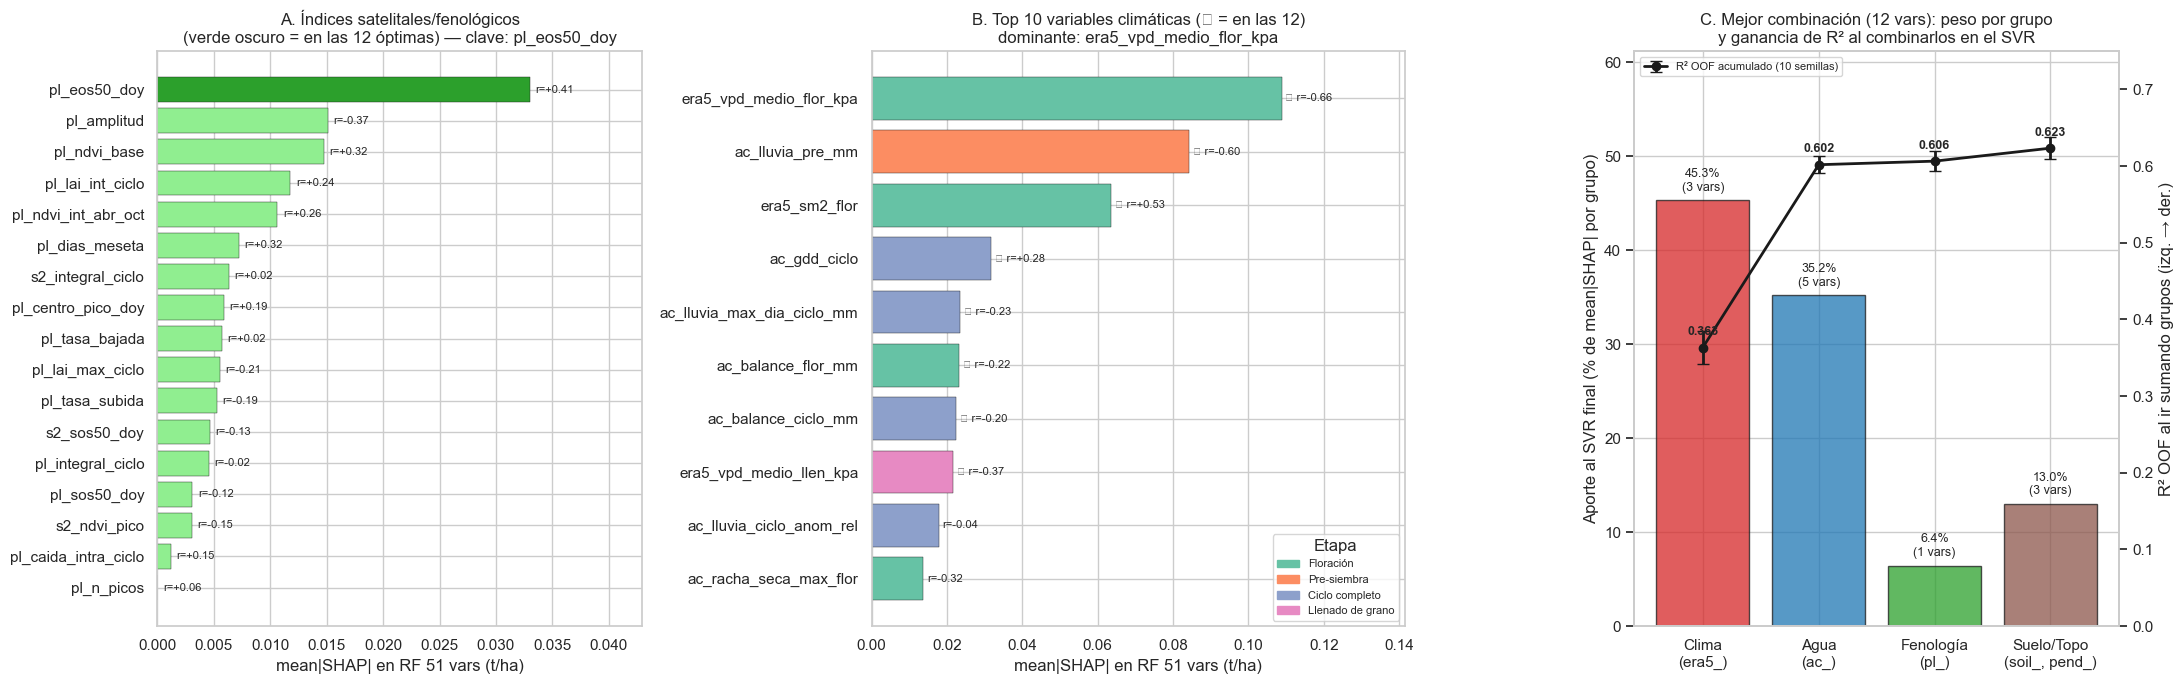

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7), gridspec_kw={'width_ratios': [1, 1.1, 1]})

# Panel A: ranking de índices satelitales/fenológicos
ax = axes[0]
t = tabla_sat.iloc[::-1]
ax.barh(t.index, t['mean|SHAP| RF51 (t/ha)'],
        color=['tab:green' if e else 'lightgreen' for e in t['En las 12']], edgecolor='k', lw=0.3)
for y_pos, (v, r) in enumerate(zip(t.index, t['Pearson r con rend.'])):
    ax.text(t.loc[v, 'mean|SHAP| RF51 (t/ha)'] + 0.0005, y_pos, f'r={r:+.2f}', va='center', fontsize=8)
ax.set_xlabel('mean|SHAP| en RF 51 vars (t/ha)')
ax.set_title(f'A. Índices satelitales/fenológicos\n(verde oscuro = en las 12 óptimas) — clave: {indice_clave}')
ax.set_xlim(0, t['mean|SHAP| RF51 (t/ha)'].max() * 1.3)

# Panel B: Top 10 climáticas, coloreadas por etapa fenológica
ax = axes[1]
t = top10_clima.iloc[::-1]
etapas_u = list(dict.fromkeys(tabla_clima['Etapa fenológica']))
pal_etapa = dict(zip(etapas_u, sns.color_palette('Set2', len(etapas_u))))
ax.barh(t.index, t['mean|SHAP| RF51 (t/ha)'], color=[pal_etapa[e] for e in t['Etapa fenológica']],
        edgecolor='k', lw=0.3)
for y_pos, v in enumerate(t.index):
    marca = '◆ ' if t.loc[v, 'En las 12'] == '✔' else ''
    ax.text(t.loc[v, 'mean|SHAP| RF51 (t/ha)'] + 0.001, y_pos, f"{marca}r={t.loc[v, 'Pearson r con rend.']:+.2f}",
            va='center', fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=pal_etapa[e], label=e) for e in etapas_u if e in set(t['Etapa fenológica'])],
          loc='lower right', fontsize=8, title='Etapa')
ax.set_xlim(0, t['mean|SHAP| RF51 (t/ha)'].max() * 1.3)
ax.set_xlabel('mean|SHAP| en RF 51 vars (t/ha)')
ax.set_title(f'B. Top 10 variables climáticas (◆ = en las 12)\ndominante: {clima_rf}')

# Panel C: peso por grupo en el SVR final + curva de ganancia en R²
ax = axes[2]
etiq = ['Clima\n(era5_)', 'Agua\n(ac_)', 'Fenología\n(pl_)', 'Suelo/Topo\n(soil_, pend_)']
barras = ax.bar(etiq, aporte_grupo_pct.values, color=[COLOR_GRUPO[g] for g in GRUPOS], alpha=0.75, edgecolor='k')
for b, p, n in zip(barras, aporte_grupo_pct.values, grupo_12.value_counts().reindex(GRUPOS).values):
    ax.text(b.get_x() + b.get_width() / 2, p + 1, f'{p:.1f}%\n({n} vars)', ha='center', fontsize=9)
ax.set_ylabel('Aporte al SVR final (% de mean|SHAP| por grupo)')
ax.set_ylim(0, aporte_grupo_pct.max() * 1.35)
ax2 = ax.twinx()
ax2.errorbar(range(len(GRUPOS)), curva['R² (10 semillas)'], yerr=curva['sd R²'], fmt='o-', color='k',
             lw=2, capsize=4, label='R² OOF acumulado (10 semillas)')
for i_, r2 in enumerate(curva['R² (10 semillas)']):
    ax2.annotate(f'{r2:.3f}', (i_, r2), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9, weight='bold')
ax2.set_ylabel('R² OOF al ir sumando grupos (izq. → der.)')
ax2.set_ylim(min(0, curva['R² (10 semillas)'].min() - 0.1), 0.75); ax2.grid(False)
ax2.legend(loc='upper left', fontsize=8)
ax.set_title('C. Mejor combinación (12 vars): peso por grupo\ny ganancia de R² al combinarlos en el SVR')
plt.tight_layout(); plt.show()

In [48]:
SIGNIFICADO = {
    'pl_eos50_doy': 'fecha (día del año) en que el NDVI cae al 50 % tras el pico: marca el fin del llenado de grano; '
                    'un fin más tardío significa más días de llenado y más rendimiento',
    'pl_sos50_doy': 'inicio de temporada (50 % de la subida del NDVI): fecha de establecimiento efectivo del cultivo',
    'pl_lai_int_ciclo': 'área foliar acumulada en el ciclo: capacidad del dosel para interceptar radiación',
    'pl_ndvi_int_abr_oct': 'NDVI integrado del ciclo: biomasa verde acumulada',
    'pl_integral_ciclo': 'integral de la curva NDVI: productividad acumulada del dosel',
    's2_integral_ciclo': 'integral NDVI de Sentinel-2: biomasa verde acumulada',
    'era5_vpd_medio_flor_kpa': 'déficit de presión de vapor en floración: demanda evaporativa del aire; un VPD alto '
                               'cierra estomas, reduce la fecundación y el número de granos',
    'era5_sm2_flor': 'humedad del suelo (7–28 cm) en floración: agua disponible en la etapa más sensible',
    'ac_lluvia_pre_mm': 'lluvia antes de la siembra: recarga del perfil y condiciones de establecimiento',
    'ac_balance_ciclo_mm': 'balance lluvia − demanda en el ciclo: excedente o déficit hídrico acumulado',
    'ac_gdd_ciclo': 'grados-día del ciclo: energía térmica acumulada (ciclos más cálidos = más cortos)',
}
sig = lambda v: SIGNIFICADO.get(v, 'ver diccionario de variables')

r2_12, rmse_12 = fila12['R² (10 semillas)'], fila12['RMSE (10 semillas)']
m_rf51 = calcular_metricas(y_train, y_oof_50vars)
linea_ic_svr = (chr(10) + f'    En el SVR final: {shap_svr12[indice_clave]:.4f} t/ha (|SHAP|) y ΔRMSE por permutación = '
                f'{perm_svr_media[indice_clave]:.4f} t/ha.' if indice_clave in vars_reducido else '')
linea_clima_svr = (chr(10) + f'    (En el SVR final, la de mayor peso por permutación es {clima_svr}: '
                   f'ΔRMSE = {perm_svr_media[clima_svr]:.4f} t/ha.)' if clima_svr != clima_rf else '')
texto = f'''
{'=' * 110}
SÍNTESIS EJECUTIVA — VARIABLES CLAVE PARA LA PREDICCIÓN DEL RENDIMIENTO DE CEBADA
{'=' * 110}
• ÍNDICE CLAVE: {indice_clave}
    Impacto medio: {shap51[indice_clave]:.4f} t/ha (|SHAP|, RF 51 vars; {shap51_pct[indice_clave]:.1f}% del total y
    {tabla_sat.loc[indice_clave, '% dentro de fenología']:.1f}% de todo el aporte fenológico).{linea_ic_svr}
    Correlación con el rendimiento r = {corr_y[indice_clave]:+.3f}; por sí solo explica R² OOF = {ic['R² OOF solo (SVR)']:.3f}.
    Significado: {sig(indice_clave)}.

• VARIABLE CLIMÁTICA: {clima_rf}  [{etapa(clima_rf)}]
    Impacto medio: {shap51[clima_rf]:.4f} t/ha (|SHAP|, RF 51 vars; {shap51_pct[clima_rf]:.1f}% del total — la variable nº 1 de las 51).
    En el SVR final: {shap_svr12[clima_rf]:.4f} t/ha (|SHAP|) y ΔRMSE por permutación = {perm_svr_media[clima_rf]:.4f} t/ha.
    Correlación con el rendimiento r = {corr_y[clima_rf]:+.3f}.
    Significado: {sig(clima_rf)}.{linea_clima_svr}

• MEJOR COMBINACIÓN: las {K_optimo} variables óptimas
    {', '.join(vars_reducido)}
    Aporte en el SVR: {' | '.join(f'{g} {p:.1f}%' for g, p in aporte_grupo_pct.items())}.
    SVR con las 12 (10 semillas): R² = {r2_12:.3f}, RMSE = {rmse_12:.3f} t/ha.
      vs Solo Clima/Agua ........ ΔR² = {r2_12 - fila_ca['R² (10 semillas)']:+.3f} | ΔRMSE = {rmse_12 - fila_ca['RMSE (10 semillas)']:+.3f} t/ha
      vs mejor grupo aislado .... ΔR² = {r2_12 - fila_ais['R² (10 semillas)']:+.3f} | ΔRMSE = {rmse_12 - fila_ais['RMSE (10 semillas)']:+.3f} t/ha ({mejor_aislado})
      vs RF con las 51 variables  ΔR² = {r2_12 - m_rf51['R2']:+.3f} | ΔRMSE = {rmse_12 - m_rf51['RMSE']:+.3f} t/ha (RF 51, seed 42)
{'=' * 110}
'''
print(texto)


SÍNTESIS EJECUTIVA — VARIABLES CLAVE PARA LA PREDICCIÓN DEL RENDIMIENTO DE CEBADA
• ÍNDICE CLAVE: pl_eos50_doy
    Impacto medio: 0.0330 t/ha (|SHAP|, RF 51 vars; 4.1% del total y
    24.0% de todo el aporte fenológico).
    En el SVR final: 0.0494 t/ha (|SHAP|) y ΔRMSE por permutación = 0.0158 t/ha.
    Correlación con el rendimiento r = +0.408; por sí solo explica R² OOF = 0.063.
    Significado: fecha (día del año) en que el NDVI cae al 50 % tras el pico: marca el fin del llenado de grano; un fin más tardío significa más días de llenado y más rendimiento.

• VARIABLE CLIMÁTICA: era5_vpd_medio_flor_kpa  [Floración]
    Impacto medio: 0.1088 t/ha (|SHAP|, RF 51 vars; 13.7% del total — la variable nº 1 de las 51).
    En el SVR final: 0.1951 t/ha (|SHAP|) y ΔRMSE por permutación = 0.0828 t/ha.
    Correlación con el rendimiento r = -0.661.
    Significado: déficit de presión de vapor en floración: demanda evaporativa del aire; un VPD alto cierra estomas, reduce la fecundación y el núm

### 9.1 Conclusiones

- **Índice clave: `pl_eos50_doy` (Planet, fin de temporada: día del año en que el NDVI cae al 50 % tras el pico).**
  - **Peso relativo:** es el índice satelital/fenológico más relevante. Tiene un impacto medio de **0.033 t/ha** (|SHAP|) en el RF de 51 variables, puesto 5 de 51, y concentra el **24 % de todo el aporte fenológico**. En el SVR final pesa **0.049 t/ha** (5.6 %) y su ΔRMSE por permutación es de 0.016 t/ha.
  - **Dirección:** positiva (r = +0.41). Un fin de temporada más tardío significa un **llenado de grano más largo** y más rendimiento. Una senescencia anticipada, por estrés o por exceso de agua como en AGC_042, lo recorta.
  - **Matiz:** por sí solo explica poco (R² fuera de pliegue de 0.06) y es el único índice satelital que entra en las 12. Su valor es **complementario**: captura la duración real del ciclo, que el clima no mide directamente.

- **Variable climática dominante: `era5_vpd_medio_flor_kpa` (déficit de presión de vapor en floración).**
  - **Peso relativo:** es la **variable número 1 de las 51**, con 0.109 t/ha (13.7 % del SHAP total). En el SVR final su peso es todavía mayor: **0.195 t/ha** (22 % del modelo) y un **ΔRMSE de 0.083 t/ha** al permutarla, el doble que la siguiente. Las dos lentes coinciden.
  - **Dirección:** negativa (r = −0.66). Un aire más seco en floración aumenta la demanda evaporativa, provoca cierre estomático y aborto floral, y reduce el **número de granos**, el componente del rendimiento que se fija en esa etapa.
  - **Variables que la acompañan:** la humedad del suelo en floración (`era5_sm2_flor`, r = +0.53) y el VPD en llenado (segunda en permutación del SVR). Juntas confirman que **la ventana floración–llenado** es donde se define el rendimiento.

- **Mejor combinación: las 12 variables óptimas.**
  - **Variables por grupo:**
    - **Clima:** `era5_vpd_medio_flor_kpa`, `era5_sm2_flor`, `era5_vpd_medio_llen_kpa`.
    - **Agua:** `ac_lluvia_pre_mm`, `ac_gdd_ciclo`, `ac_lluvia_max_dia_ciclo_mm`, `ac_balance_flor_mm`, `ac_balance_ciclo_mm`.
    - **Fenología:** `pl_eos50_doy`.
    - **Suelo y topografía:** `soil_agua_disp_mm`, `soil_soc_g_kg`, `pend_media_grados`.
  - **Aporte en el SVR:** clima **45 %**, agua **35 %**, suelo y topografía **13 %**, fenología **6 %**.
  - **Desempeño (10 semillas):** con las 12 variables, el SVR alcanza **R² = 0.623 y RMSE = 0.520 t/ha**:
    - Frente al mejor grupo aislado (solo agua, R² 0.504): **+0.120 de R² y −0.077 t/ha de RMSE**.
    - Frente a clima y agua juntos: +0.022 de R² y −0.015 t/ha.
    - Frente al RF con las 51 variables: **+0.091 de R² y −0.059 t/ha**.
  - **Dónde está la sinergia:** el salto grande ocurre al **combinar clima atmosférico y agua** (R² de 0.36 y 0.50 por separado, 0.60 juntos). Fenología, suelo y topografía añaden ganancias pequeñas (+0.005 y +0.017), del orden de la variación entre semillas (desviación estándar de unos 0.01–0.014). Son ajustes finos, no el núcleo del modelo.

> **Cautela interpretativa:** `ac_lluvia_pre_mm` tiene correlación **negativa** con el rendimiento (r = −0.60). En este conjunto, más lluvia antes de la siembra coincide con zonas más húmedas y de menor rendimiento, un patrón coherente con el exceso hídrico visto en Singuilucan (7.2). Es una asociación espacial, no necesariamente causal: no debe leerse como que la lluvia previa a la siembra perjudique al cultivo por sí misma.